In [1]:
# ZLEMA TREND + MARTINGALE LEVELS - RULE AND TRADES ONLY
# Reads data/CRYPTO/<SYMBOL>.parquet. Saves trades.parquet / trades.csv.

import numpy as np, pandas as pd
from pathlib import Path
from numba import njit

ATR_PERIOD, WEIGHT_BY_LEVEL = 14, True
REALISTIC = True        # True = gap-aware stop fills + cost; False = exact locked-cell fills (-1R / +RR, no cost)
COST_ATR  = 0.3        # round-trip cost per trade, in ATR (only used when REALISTIC)
DATA_DIR  = "data"

# symbol: (fast, slow, sl_atr, rr, max_levels)
CONFIG = {
    "LTCUSDT_H4":  (15,  60, 1.75, 2.5, 3),
    "XRPUSDT_H4":  (15, 100, 1.75, 2.0, 2),
    "ADAUSDT_H4":  (25,  70, 1.75, 2.0, 3),
    "ETHUSDT_H4":  (25,  60, 2.00, 2.0, 2),
    "LINKUSDT_H4": (20,  70, 2.50, 1.5, 5),
    "BTCUSDT_H4":  (15,  80, 1.75, 2.5, 3),
    "DOGEUSDT_H4": (35,  80, 1.75, 2.0, 3),
    "TRXUSDT_H4":  (35,  60, 1.50, 3.0, 1),
    "SOLUSDT_H4":  (25,  60, 1.75, 2.5, 1),
    "BNBUSDT_H4":  (50,  80, 2.00, 1.5, 1),
}

# ---------------- indicators ----------------
@njit(cache=False)
def ema_numba(x, period):
    n = len(x); out = np.full(n, np.nan)
    if n == 0: return out
    alpha = 2.0 / (period + 1.0); start = -1
    for i in range(n):
        if np.isfinite(x[i]): start = i; break
    if start == -1: return out
    out[start] = x[start]
    for i in range(start + 1, n):
        out[i] = alpha * x[i] + (1.0 - alpha) * out[i - 1] if np.isfinite(x[i]) else out[i - 1]
    return out

@njit(cache=False)
def zlema_numba(close, period):
    n = len(close); lag = (period - 1) // 2; adjusted = np.full(n, np.nan)
    for i in range(n):
        j = i - lag
        if j >= 0: adjusted[i] = 2.0 * close[i] - close[j]
    return ema_numba(adjusted, period)

@njit(cache=False)
def atr_numba(high, low, close, period):
    n = len(close); tr = np.full(n, np.nan)
    if n == 0: return tr
    tr[0] = high[0] - low[0]
    for i in range(1, n):
        tr[i] = max(high[i] - low[i], abs(high[i] - close[i - 1]), abs(low[i] - close[i - 1]))
    return ema_numba(tr, period)

@njit(cache=False)
def trend_numba(close, fast, slow):
    f = zlema_numba(close, fast); s = zlema_numba(close, slow); n = len(close)
    trend = np.zeros(n, dtype=np.int8)
    for i in range(n):
        if np.isfinite(f[i]) and np.isfinite(s[i]):
            if f[i] > s[i]: trend[i] = 1
            elif f[i] < s[i]: trend[i] = -1
    return trend

# ---------------- trade rule / engine ----------------
@njit(cache=False)
def engine_log(open_, high, low, close, atr, trend, sl_atr, rr, max_levels, weight, realistic, cost_r):
    n = len(close)
    ei_a = np.empty(n, np.int64); xi_a = np.empty(n, np.int64)
    dir_a = np.empty(n, np.int64); lv_a = np.empty(n, np.int64); R_a = np.empty(n)
    k = 0; position = 0; level = 0; entry = 0.0; stop = 0.0; target = 0.0; risk0 = 1.0; ei = 0
    want_reentry = False; reentry_direction = 0
    for i in range(1, n):
        current_trend = trend[i]
        if current_trend == 0: continue
        if position != 0:
            exit_type = 0; px = 0.0
            if position == 1:
                if low[i] <= stop:
                    exit_type = -1; px = stop
                    if realistic and open_[i] < stop: px = open_[i]
                elif high[i] >= target:
                    exit_type = 1; px = target
            else:
                if high[i] >= stop:
                    exit_type = -1; px = stop
                    if realistic and open_[i] > stop: px = open_[i]
                elif low[i] <= target:
                    exit_type = 1; px = target
            if exit_type != 0:
                if realistic: base = position * (px - entry) / risk0 - cost_r
                else: base = -1.0 if exit_type == -1 else rr
                r = base * level if weight else base
                ei_a[k] = ei; xi_a[k] = i; dir_a[k] = position; lv_a[k] = level; R_a[k] = r; k += 1
                if exit_type == -1:
                    if level < max_levels:
                        level += 1; want_reentry = True; reentry_direction = position
                    else:
                        level = 0; want_reentry = False; reentry_direction = 0
                else:
                    level = 0; want_reentry = False; reentry_direction = 0
                position = 0
                continue
        if position == 0 and want_reentry and current_trend == reentry_direction:
            risk = atr[i] * sl_atr
            if np.isfinite(risk) and risk > 0.0:
                position = reentry_direction; entry = close[i]; ei = i; risk0 = risk
                if position == 1: stop = entry - risk; target = entry + risk * rr
                else: stop = entry + risk; target = entry - risk * rr
                want_reentry = False
            continue
        previous_trend = trend[i - 1]
        fresh_signal = previous_trend != 0 and current_trend != previous_trend
        if position == 0 and not want_reentry and fresh_signal:
            risk = atr[i] * sl_atr
            if not np.isfinite(risk) or risk <= 0.0: continue
            position = current_trend; level = 1; entry = close[i]; ei = i; risk0 = risk
            if position == 1: stop = entry - risk; target = entry + risk * rr
            else: stop = entry + risk; target = entry - risk * rr
    return ei_a[:k], xi_a[:k], dir_a[:k], lv_a[:k], R_a[:k]

# ---------------- data ----------------
def load_symbol(sym):
    p = Path(DATA_DIR, "CRYPTO", f"{sym}.parquet")
    if not p.exists(): return None
    d = pd.read_parquet(p)
    if "complete" in d: d = d[d["complete"]]
    d["timestamp"] = pd.to_datetime(d["timestamp"], utc=True)
    d = d.sort_values("timestamp")
    h, l, c, o = [pd.to_numeric(d[x], errors="coerce").to_numpy(np.float64) for x in ("high", "low", "close", "open")]
    ok = np.isfinite(h) & np.isfinite(l) & np.isfinite(c) & (h > 0) & (l > 0) & (c > 0)
    o = np.where(np.isfinite(o) & (o > 0), o, c)
    return (pd.DatetimeIndex(d["timestamp"])[ok], np.ascontiguousarray(o[ok]), np.ascontiguousarray(h[ok]),
            np.ascontiguousarray(l[ok]), np.ascontiguousarray(c[ok]))

# ---------------- run ----------------
frames, missing = [], []
for sym, (fast, slow, sl_atr, rr, max_levels) in CONFIG.items():
    x = load_symbol(sym)
    if x is None: missing.append(sym); continue
    t, o, h, l, c = x
    atr = atr_numba(h, l, c, ATR_PERIOD)
    trend = trend_numba(c, fast, slow)
    ei, xi, dr, lvl, R = engine_log(o, h, l, c, atr, trend, sl_atr, rr, max_levels, WEIGHT_BY_LEVEL,
                                    REALISTIC, COST_ATR / sl_atr if REALISTIC else 0.0)
    frames.append(pd.DataFrame({"symbol": sym, "entry_time": t[ei], "exit_time": t[xi],
                                "dir": dr, "level": lvl, "R": R}))
if missing: print("MISSING FILES:", missing)

trades = pd.concat(frames, ignore_index=True).sort_values(["entry_time", "symbol"]).reset_index(drop=True)
print(trades.groupby("symbol").agg(trades=("R", "size"), totalR=("R", "sum"), meanR=("R", "mean")).round(3))
print(f"\nTotal trades: {len(trades)}")
trades.to_parquet("trades.parquet")
trades.to_csv("trades.csv", index=False)
print("saved trades.parquet and trades.csv")

             trades   totalR  meanR
symbol                             
ADAUSDT_H4      466  105.857  0.227
BNBUSDT_H4      415   24.870  0.060
BTCUSDT_H4      423   23.314  0.055
DOGEUSDT_H4     329   74.257  0.226
ETHUSDT_H4      446   56.150  0.126
LINKUSDT_H4     319   85.760  0.269
LTCUSDT_H4      376  150.929  0.401
SOLUSDT_H4      291   47.614  0.164
TRXUSDT_H4      440   26.925  0.061
XRPUSDT_H4      369   49.914  0.135

Total trades: 3874
saved trades.parquet and trades.csv


In [6]:
import numpy as np
import pandas as pd
from scipy import stats

TRADES_FILE = "trades.parquet"
SEED = 20261124
N_BOOT = 20000
N_PERM = 20000

rng = np.random.default_rng(SEED)

trades = pd.read_parquet(TRADES_FILE).copy()
trades["entry_time"] = pd.to_datetime(trades["entry_time"], utc=True, errors="coerce")
trades["exit_time"] = pd.to_datetime(trades["exit_time"], utc=True, errors="coerce")
trades["R"] = pd.to_numeric(trades["R"], errors="coerce")
trades = trades.dropna(subset=["entry_time", "exit_time", "R", "symbol"]).sort_values("entry_time").reset_index(drop=True)

R = trades["R"].to_numpy(dtype=float)
print(f"Loaded {len(R):,} trades | Observed Mean R: {R.mean():+.6f} | Total R: {R.sum():+.4f}")

Loaded 3,874 trades | Observed Mean R: +0.166647 | Total R: +645.5910


```Research Question 1```

Is mean R statistically > 0?

```Test 1A: One-Sample Parametric t-Test```

In [8]:
t_stat, t_two = stats.ttest_1samp(R, 0.0)
t_one = t_two / 2 if t_stat > 0 else 1.0 - t_two / 2

print(f"t statistic : {t_stat:.6f}")
print(f"one-sided p : {t_one:.8e}")
print(f"n           : {len(R):,}")

t statistic : 4.207899
one-sided p : 1.31799178e-05
n           : 3,874


### Test 1A: One-Sample Parametric t-Test

* **Null Hypothesis ($H_0$)**: $\mu_R \le 0$ (the true mean R-multiple per trade is zero or negative).
* **Alternative Hypothesis ($H_1$)**: $\mu_R > 0$ (the true mean R-multiple per trade is strictly greater than zero).
* **Significance Level ($\alpha$)**: $\alpha = 0.05$ (one-sided test; $\alpha = 0.01$ noted as a stricter benchmark).
* **Interpretation**:
  * **Observed Result**: Across `n = 3,874` closed H4 trades, the test yields **`t = +4.2079`** with a one-sided p-value of **`p = 1.32 × 10⁻⁵`** (`0.0000132`).
  * **Decision**: Because `p < 0.05` (and also `p < 0.01`), we **reject $H_0$** in favor of $H_1$. At `t = +4.2079`, the sample mean sits more than four standard errors above zero.
  * **Caveat**: Parametric t-inference assumes independent, identically distributed (IID) trades and relies on asymptotic normality. Because this strategy uses asymmetric reward-to-risk targets (`rr` between `1.5` and `3.0`) and **Martingale level scaling** (`WEIGHT_BY_LEVEL = True`), consecutive trades along a Martingale ladder can be serially correlated and non-normal—so we verify this finding with non-parametric and resampling tests next.ext.

```Test 1B (Wilcoxon Signed-Rank Test)```

In [14]:
nonzero = R[R != 0]

try:
    w_stat, w_two = stats.wilcoxon(
        nonzero,
        alternative="greater",
        zero_method="wilcox",
        method="auto"
    )
except Exception:
    w_stat, w_two = np.nan, np.nan

print(f"Non-zero trades   : {len(nonzero):,}")
print(f"Statistic         : {w_stat}")
print(f"one-sided p       : {w_two:.8e}")

Non-zero trades   : 3,874
Statistic         : 4190129.0
one-sided p       : 1.69577732e-10


### Test 1B: Wilcoxon Signed-Rank Test

* **Null Hypothesis ($H_0$)**: The distribution of non-zero R-multiples is symmetric around `0` (no upward shift toward positive trade returns).
* **Alternative Hypothesis ($H_1$)**: The distribution of non-zero R-multiples is shifted upward above `0` (positive trade ranks outweigh negative trade ranks).
* **Significance Level ($\alpha$)**: $\alpha = 0.05$ (one-sided test; $\alpha = 0.01$ noted as a stricter benchmark).
* **Interpretation**:
  * **Observed Result**: Across all `3,874` non-zero trades (zero exact breakeven trades), the test yields **`W = 4,190,129.0`** with a one-sided p-value of **`p = 1.70 × 10⁻¹⁰`** (`0.000000000170`).
  * **Decision**: Because `p < 0.05` (and far below `0.01`), we **reject $H_0$** in favor of $H_1$. Even without assuming normality of R-multiples, the rank-weighted evidence strongly favors positive returns over negative returns.
  * **Caveat**: While the Wilcoxon test avoids parametric normality assumptions and reduces the impact of extreme outliers compared to raw means, it still treats trade observations as independent—so we continue checking sign win-rate, permutation, and resampling tests next.

```Test 1C (Sign / Binomial Test)```

In [18]:
wins = int(np.sum(R > 0))
losses = int(np.sum(R < 0))

binom = stats.binomtest(
    wins,
    wins + losses,
    p=0.5,
    alternative="greater"
)

print(f"Wins              : {wins:,}")
print(f"Losses            : {losses:,}")
print(f"Win probability   : {wins / (wins + losses):.4%}")
print(f"one-sided p       : {binom.pvalue:.8e}")

Wins              : 1,567
Losses            : 2,307
Win probability   : 40.4491%
one-sided p       : 1.00000000e+00


### Test 1C: Sign / Binomial Test

* **Null Hypothesis ($H_0$)**: $p_{\text{win}} \le 0.50$ (the true win probability across directional trades is at most 50%).
* **Alternative Hypothesis ($H_1$)**: $p_{\text{win}} > 0.50$ (the true win probability across directional trades is strictly greater than 50%).
* **Significance Level ($\alpha$)**: $\alpha = 0.05$ (one-sided test; $\alpha = 0.01$ noted as a stricter benchmark).
* **Interpretation**:
  * **Observed Result**: Out of `3,874` directional trades (`0` breakeven trades), there are **`1,567` wins** and **`2,307` losses**, giving an observed win rate of **`40.45%`** (`40.4491%`) and a one-sided p-value of **`p = 1.00000000`**.
  * **Decision**: Because `p >= 0.05` (and win rate is below `50%`), we **fail to reject $H_0$** on win frequency alone—most individual trades are losses.
  * **Caveat**: A win rate below `50%` does **not** contradict a positive strategy edge when reward-to-risk ratios (`rr` between `1.5` and `3.0`) and **Martingale level scaling** (`WEIGHT_BY_LEVEL = True`) make average winners larger than average losers. Comparing Test 1C against Tests 1A and 1B highlights that any edge comes from **payoff asymmetry and magnitude**, not winning more often than losing.

```Test 1D (Sign-Permutation Test)```

In [22]:
observed_mean = R.mean()
abs_R = np.abs(R)
perm_means = np.empty(N_PERM)

for b in range(N_PERM):
    signs = rng.choice(np.array([-1.0, 1.0]), size=len(R))
    perm_means[b] = np.mean(abs_R * signs)

perm_p = (np.sum(perm_means >= observed_mean) + 1) / (N_PERM + 1)

print(f"Observed mean R : {observed_mean:+.6f}")
print(f"Permutation p   : {perm_p:.8e}")

Observed mean R : +0.166647
Permutation p   : 4.99975001e-05


### Test 1D: Sign-Permutation Test

* **Null Hypothesis ($H_0$)**: Trade return signs are independent of trade magnitudes and follow a symmetric 50/50 sign distribution around zero, so the observed mean R (`+0.166647`) is consistent with random sign assignment over the empirical magnitudes `|R|`.
* **Alternative Hypothesis ($H_1$)**: Trade return signs align systematically with positive magnitudes `|R|` such that the observed mean R is larger than expected under random sign permutations.
* **Significance Level ($\alpha$)**: $\alpha = 0.05$ (one-sided permutation test; $\alpha = 0.01$ noted as a stricter benchmark).
* **Interpretation**:
  * **Observed Result**: Across `20,000` sign permutations over `3,874` trades, the observed mean is **`+0.166647R`** with a one-sided permutation p-value of **`p = 5.00 × 10⁻⁵`** (`1 / 20,001 = 0.0000499975`), meaning zero permuted samples in `20,000` runs matched or exceeded `+0.166647R`.
  * **Decision**: Because `p < 0.05` (and far below `0.01`), we **reject $H_0$** in favor of $H_1$. Even when holding the exact empirical distribution of trade sizes `|R|` fixed, random sign flips rarely produce a mean as high as `+0.166647R`, supporting genuine directional sign alignment rather than pure magnitude artifacts.
  * **Caveat**: Independent random sign flips break the sequential structure of Martingale ladders (where higher-level trades are conditioned on prior stop-outs) and ignore cross-asset/time clustering—so we continue testing resampling and dependence next.

```Test 1E (IID Bootstrap for Mean R)```

In [26]:
n = len(R)
boot_mean = np.empty(N_BOOT)

for b in range(N_BOOT):
    sample = R[rng.integers(0, n, size=n)]
    boot_mean[b] = np.mean(sample)

mean_lo = np.percentile(boot_mean, 2.5)
mean_med = np.percentile(boot_mean, 50.0)
mean_hi = np.percentile(boot_mean, 97.5)
prob_mean_nonpositive = np.mean(boot_mean <= 0.0)

print(f"Observed mean       : {R.mean():+.6f}")
print(f"Bootstrap median    : {mean_med:+.6f}")
print(f"95% CI              : [{mean_lo:+.6f}, {mean_hi:+.6f}]")
print(f"Bootstrap P(mean<=0): {prob_mean_nonpositive:.4%}")

Observed mean       : +0.166647
Bootstrap median    : +0.166704
95% CI              : [+0.089226, +0.243976]
Bootstrap P(mean<=0): 0.0000%


### Test 1E: IID Bootstrap — Mean R

* **Null Hypothesis ($H_0$)**: $\mu_R \le 0$ (the empirical bootstrap distribution of mean R does not support a strictly positive mean above zero; the 95% confidence interval covers or falls below zero).
* **Alternative Hypothesis ($H_1$)**: $\mu_R > 0$ (the empirical bootstrap distribution supports a strictly positive mean R, with a 95% confidence interval lying entirely above zero).
* **Significance Level ($\alpha$)**: $\alpha = 0.05$ (corresponding to a 95% two-sided percentile confidence interval `[2.5%, 97.5%]` and `P(mean <= 0) < 0.05`).
* **Interpretation**:
  * **Observed Result**: Across `20,000` IID resamples of `3,874` trades, the observed mean is **`+0.166647R`**, the bootstrap median is **`+0.166704R`**, the 95% confidence interval is **`[+0.089226R, +0.243976R]`**, and **`P(mean <= 0) = 0.0000%`** (zero resamples out of `20,000` had a mean less than or equal to zero).
  * **Decision**: Because the entire 95% confidence interval lies strictly above zero (`mean_lo = +0.089226 > 0`) and `P(mean <= 0) = 0.0000% < 0.05`, we **reject $H_0$** in favor of $H_1$. Even under heavy resampling uncertainty, the lower bound of the 95% CI sits near `+0.089R` per trade.
  * **Caveat**: Standard IID bootstrap treats every trade as an independent draw. Because Martingale re-entries (`level > 1`) occur conditionally after prior losses and trades span multiple crypto pairs over time, we next test whether the edge holds up to broader resampling and robustness chion 2**.

### Conclusion — Research Question 1: Is Mean R Statistically > 0?

* **Verdict**: **Yes — mean R is statistically significantly greater than zero (`+0.166647R` across `3,874` trades), driven by payoff asymmetry rather than a >50% win rate.**
* **Summary of Evidence (Tests 1A–1E)**:
  * **Parametric & Non-Parametric Location (Tests 1A & 1B)**: Both the one-sample t-test (`t = +4.2079`, one-sided `p = 1.32 × 10⁻⁵`) and Wilcoxon signed-rank test (`W = 4,190,129.0`, one-sided `p = 1.70 × 10⁻¹⁰`) strongly reject `mean/location <= 0` at `α = 0.05` and `α = 0.01`.
  * **Directional Sign Alignment (Test 1D)**: The sign-permutation test (`p = 5.00 × 10⁻⁵` across `20,000` flips) confirms that holding trade magnitudes `|R|` constant, random sign assignment rarely reaches `+0.166647R`.
  * **IID Bootstrap Stability (Test 1E)**: Across `20,000` IID resamples, the 95% confidence interval for mean R is **`[+0.089226R, +0.243976R]`** with **`P(mean <= 0) = 0.0000%`**.
  * **Win-Rate Nuance (Test 1C)**: The win rate is **`40.45%`** (`1,567` wins vs. `2,307` losses; binomial one-sided `p = 1.0000` against `50%`). Rather than winning more than half the time, the strategy relies on larger winning payoffs (`rr` of `1.5`–`3.0` and Martingale level weighting) outweighing more frequent smaller losses.
* **Caveat / Next Step**: Because IID tests and sign permutations treat trades as independent—and Martingale re-entries (`level > 1`) introduce sequential dependence across trades, symbols, and time—a statistically positive trade-level mean R is necessary, **not sufficient**, for deployment. We next test **Question 2: Is the edge robust to resampling?**

**Research Question 2:
Is the edge robust to resampling?**

```Test 2A: IID Bootstrap — Profit Factor```

In [41]:
def pf_value(x):
    x = np.asarray(x, dtype=float)
    gross_profit = x[x > 0].sum()
    gross_loss = -x[x < 0].sum()
    if gross_loss <= 0:
        return np.inf
    return gross_profit / gross_loss

n = len(R)
boot_pf = np.empty(N_BOOT)

for b in range(N_BOOT):
    sample = R[rng.integers(0, n, size=n)]
    boot_pf[b] = pf_value(sample)

pf_obs = pf_value(R)
pf_lo = np.percentile(boot_pf, 2.5)
pf_med = np.percentile(boot_pf, 50.0)
pf_hi = np.percentile(boot_pf, 97.5)
prob_pf_le_1 = np.mean(boot_pf <= 1.0)

print(f"Observed PF       : {pf_obs:.6f}")
print(f"Bootstrap median  : {pf_med:.6f}")
print(f"95% CI            : [{pf_lo:.6f}, {pf_hi:.6f}]")
print(f"P(PF <= 1)        : {prob_pf_le_1:.4%}")

Observed PF       : 1.170047
Bootstrap median  : 1.170416
95% CI            : [1.088860, 1.256813]
P(PF <= 1)        : 0.0000%


### Test 2A: IID Bootstrap — Profit Factor

* **Null Hypothesis ($H_0$)**: $\text{PF} \le 1.0$ (gross profits do not exceed gross losses in R-multiples; the bootstrap distribution covers or falls at/below breakeven `PF = 1.0`).
* **Alternative Hypothesis ($H_1$)**: $\text{PF} > 1.0$ (gross profits exceed gross losses in R-multiples, with a 95% confidence interval lying strictly above `1.0`).
* **Significance Level ($\alpha$)**: $\alpha = 0.05$ (corresponding to a 95% two-sided percentile confidence interval `[2.5%, 97.5%]` and `P(PF <= 1) < 0.05`).
* **Interpretation**:
  * **Observed Result**: Across `20,000` IID resamples of `3,874` trades, the observed Profit Factor is **`1.170047`**, the bootstrap median is **`1.170416`**, the 95% confidence interval is **`[1.088860, 1.256813]`**, and **`P(PF <= 1) = 0.0000%`** (zero resamples out of `20,000` dropped to or below `1.0`).
  * **Decision**: Because the entire 95% confidence interval lies strictly above `1.0` (`pf_lo = 1.088860 > 1.0`) and `P(PF <= 1) = 0.0000% < 0.05`, we **reject $H_0$** in favor of $H_1$. Gross profits remain roughly `8.9%` to `25.7%` above gross losses across the 95% resample band.
  * **Caveat**: While `PF = 1.1700` is statistically well above `1.0` under IID resampling, a `1.17` profit factor leaves a relatively modest buffer before real-world execution frictions are stressed. 2 next.

Test 2B: IID Bootstrap — Trade Sharpe Ratio

In [46]:
n = len(R)
boot_sharpe = np.empty(N_BOOT)

for b in range(N_BOOT):
    sample = R[rng.integers(0, n, size=n)]
    sd = np.std(sample, ddof=1)
    boot_sharpe[b] = np.mean(sample) / sd if sd > 0 else np.nan

sh_obs = np.mean(R) / np.std(R, ddof=1)
sh_lo = np.nanpercentile(boot_sharpe, 2.5)
sh_med = np.nanpercentile(boot_sharpe, 50.0)
sh_hi = np.nanpercentile(boot_sharpe, 97.5)
prob_sh_le_0 = np.mean(boot_sharpe <= 0.0)

print(f"Observed Trade Sharpe : {sh_obs:.6f}")
print(f"Bootstrap median      : {sh_med:.6f}")
print(f"95% CI                : [{sh_lo:.6f}, {sh_hi:.6f}]")
print(f"P(Sharpe <= 0)        : {prob_sh_le_0:.4%}")

Observed Trade Sharpe : 0.067606
Bootstrap median      : 0.067473
95% CI                : [0.036805, 0.098411]
P(Sharpe <= 0)        : 0.0000%


### Test 2B: IID Bootstrap — Per-Trade Sharpe Ratio

* **Null Hypothesis ($H_0$)**: $\text{SR}_{\text{trade}} \le 0.0$ (risk-adjusted return per trade in R-multiples is zero or negative; the bootstrap distribution covers or falls at/below zero).
* **Alternative Hypothesis ($H_1$)**: $\text{SR}_{\text{trade}} > 0.0$ (risk-adjusted return per trade in R-multiples is strictly positive, with a 95% confidence interval lying above zero).
* **Significance Level ($\alpha$)**: $\alpha = 0.05$ (corresponding to a 95% two-sided percentile confidence interval `[2.5%, 97.5%]` and `P(Sharpe <= 0) < 0.05`).
* **Interpretation**:
  * **Observed Result**: Across `20,000` IID resamples of `3,874` trades, the observed per-trade Sharpe ratio is **`0.067606`**, the bootstrap median is **`0.067473`**, the 95% confidence interval is **`[0.036805, 0.098411]`**, and **`P(Sharpe <= 0) = 0.0000%`** (zero resamples out of `20,000` dropped to or below `0.0`).
  * **Decision**: Because the entire 95% confidence interval lies strictly above zero (`sh_lo = 0.036805 > 0.0`) and `P(Sharpe <= 0) = 0.0000% < 0.05`, we **reject $H_0$** in favor of $H_1$. Per-trade risk-adjusted return stays positive across all `20,000` bootstrap draws.
  * **Caveat**: A per-trade Sharpe around `0.068` reflects high trade-to-trade R volatility relative to average R per trade—meaning equity swings on a trade-by-trade basis are substantial even when the mean is positive.

Test 2C (Monte Carlo Trade-Order Shuffling)

In [54]:
N_MC = int(globals().get("N_MC", globals().get("N_BOOT", 20_000)))

def max_drawdown_r(x):
    x = np.asarray(x, dtype=float)
    if len(x) == 0:
        return 0.0
    eq = np.concatenate(([0.0], np.cumsum(x)))
    peak = np.maximum.accumulate(eq)
    dd = peak - eq
    return float(np.max(dd))

n = len(R)
mc_final_r = np.empty(N_MC, dtype=float)
mc_max_dd = np.empty(N_MC, dtype=float)

for b in range(N_MC):
    perm = R[rng.permutation(n)]
    mc_final_r[b] = np.sum(perm)
    mc_max_dd[b] = max_drawdown_r(perm)

obs_total_r = float(np.sum(R))
obs_max_dd = max_drawdown_r(R)

print(f"Monte Carlo runs         : {N_MC:,}")
print(f"Observed Total R         : {obs_total_r:+.2f}")
print(f"MC Final R 50th pct      : {np.percentile(mc_final_r, 50):+.2f}")
print(f"Observed Max DD (R)      : {obs_max_dd:.2f}")
print(f"MC Max DD 50th pct (R)   : {np.percentile(mc_max_dd, 50):.2f}")
print(f"MC Max DD 95th pct (R)   : {np.percentile(mc_max_dd, 95):.2f}")
print(f"MC Max DD 99th pct (R)   : {np.percentile(mc_max_dd, 99):.2f}")
print(f"P(MC Max DD >= Obs DD)   : {np.mean(mc_max_dd >= obs_max_dd):.4%}")

Monte Carlo runs         : 20,000
Observed Total R         : +645.59
MC Final R 50th pct      : +645.59
Observed Max DD (R)      : 159.55
MC Max DD 50th pct (R)   : 68.12
MC Max DD 95th pct (R)   : 104.60
MC Max DD 99th pct (R)   : 125.77
P(MC Max DD >= Obs DD)   : 0.0400%


### Test 2C: Monte Carlo Trade-Order Shuffling — Max Drawdown Path Dependence

* **Null Hypothesis ($H_0$)**: Trade order is exchangeable/unclustered with respect to drawdown severity, so the observed maximum drawdown (`159.55R`) is consistent with random trade-order permutations (`P(MC Max DD >= Obs DD) >= 0.05`).
* **Alternative Hypothesis ($H_1$)**: Trade outcomes exhibit adverse serial/regime clustering along the actual historical sequence such that observed maximum drawdown exceeds what random trade-order shuffling typically produces (`P(MC Max DD >= Obs DD) < 0.05`).
* **Significance Level ($\alpha$)**: $\alpha = 0.05$ (one-sided upper-tail test on maximum drawdown; total R is invariant to trade ordering and equals `+645.59R` across all permutations).
* **Interpretation**:
  * **Observed Result**: Across `20,000` random trade-order permutations of `3,874` trades, total cumulative return stays fixed at **`+645.59R`**, while the observed maximum drawdown is **`159.55R`** compared to a Monte Carlo median of **`68.12R`**, 95th percentile of **`104.60R`**, and 99th percentile of **`125.77R`**, yielding **`P(MC Max DD >= Obs DD) = 0.0400%`** (`8` out of `20,000` runs).
  * **Decision**: Because `P(MC Max DD >= Obs DD) = 0.0400% < 0.05` (well below `0.01`), we **reject $H_0$** in favor of $H_1$. Although total cumulative R (`+645.59R`) is preserved regardless of trade order, the observed drawdown (`159.55R`) is substantially worse than typical random shuffles—pointing to **adverse regime or Martingale loss clustering** in the chronological sequence.
  * **Caveat**: Shuffling individual closed trades breaks chronological time blocks and multi-asset/Martingale serial structure, so shuffled drawdown percentiles understate risk when consecutive losses or concurrent symbol drawdowns cluster together.** next.

Test 2D: Moving-Block Bootstrap — Mean R & Profit Factor

In [59]:
BLOCK_LEN = int(globals().get("BLOCK_LEN", 20))
n = len(R)
n_blocks = int(np.ceil(n / BLOCK_LEN))
boot_block_mean = np.empty(N_BOOT, dtype=float)
boot_block_pf = np.empty(N_BOOT, dtype=float)

for b in range(N_BOOT):
    starts = rng.integers(0, max(1, n - BLOCK_LEN + 1), size=n_blocks)
    sample = np.concatenate([R[s : s + BLOCK_LEN] for s in starts])[:n]
    boot_block_mean[b] = np.mean(sample)
    boot_block_pf[b] = pf_value(sample)

bmean_lo, bmean_med, bmean_hi = np.percentile(boot_block_mean, [2.5, 50.0, 97.5])
bpf_lo, bpf_med, bpf_hi = np.percentile(boot_block_pf, [2.5, 50.0, 97.5])

print(f"Block length          : {BLOCK_LEN}")
print(f"Block Boot Mean med   : {bmean_med:+.6f}")
print(f"Block Boot Mean 95% CI: [{bmean_lo:+.6f}, {bmean_hi:+.6f}]")
print(f"P(Block Mean <= 0)    : {np.mean(boot_block_mean <= 0.0):.4%}")
print(f"Block Boot PF med     : {bpf_med:.6f}")
print(f"Block Boot PF 95% CI  : [{bpf_lo:.6f}, {bpf_hi:.6f}]")
print(f"P(Block PF <= 1)      : {np.mean(boot_block_pf <= 1.0):.4%}")

Block length          : 20
Block Boot Mean med   : +0.168707
Block Boot Mean 95% CI: [+0.071415, +0.268052]
P(Block Mean <= 0)    : 0.0600%
Block Boot PF med     : 1.172332
Block Boot PF 95% CI  : [1.069768, 1.286407]
P(Block PF <= 1)      : 0.0600%


### Test 2D: Moving-Block Bootstrap — Mean R & Profit Factor

* **Null Hypothesis ($H_0$)**: When preserving contiguous blocks of `20` trades, true mean R is less than or equal to zero ($\mu_R \le 0$) and profit factor is less than or equal to one ($\text{PF} \le 1.0$).
* **Alternative Hypothesis ($H_1$)**: When preserving contiguous blocks of `20` trades, true mean R is strictly greater than zero ($\mu_R > 0$) and profit factor is strictly greater than one ($\text{PF} > 1.0$).
* **Significance Level ($\alpha$)**: $\alpha = 0.05$ (corresponding to two-sided 95% block-bootstrap confidence intervals `[2.5%, 97.5%]` and tail probabilities `P(Block Mean <= 0) < 0.05` and `P(Block PF <= 1) < 0.05`).
* **Interpretation**:
  * **Observed Result**: Across `20,000` moving-block resamples (`BLOCK_LEN = 20`) of `3,874` trades, the block-bootstrap median mean R is **`+0.168707R`** with a 95% confidence interval of **`[+0.071415R, +0.268052R]`** and **`P(Block Mean <= 0) = 0.0600%`**. For Profit Factor, the block-bootstrap median is **`1.172332`** with a 95% confidence interval of **`[1.069768, 1.286407]`** and **`P(Block PF <= 1) = 0.0600%`**.
  * **Decision**: Because both 95% confidence intervals lie strictly above their breakeven thresholds (`+0.071415 > 0` for mean R and `1.069768 > 1.0` for Profit Factor) and both tail probabilities are `0.0600% < 0.05`, we **reject $H_0$** in favor of $H_1$. Compared to IID bootstrap (`[+0.089226, +0.243976]` and `[1.088860, 1.256813]`), the confidence intervals widen slightly—reflecting serial correlation within 20-trade blocks—yet the positive edge remains intact.
  * **Caveat**: Fixed-length blocks of `20` trades capture local serial dependence along the concatenated trade stream, but do not directly model calendar-time overlap across multiple crypto pairs or Martingale ladder conditioning across separate symbols.

Test 2E: Stationary Bootstrap — Politis–Romano Random Block Length

In [64]:
AVG_BLOCK_LEN = float(globals().get("AVG_BLOCK_LEN", 20.0))
p_restart = 1.0 / AVG_BLOCK_LEN
n = len(R)

# Vectorized generation of all N_BOOT index paths of length n: shape (N_BOOT, n)
restarts = rng.random((N_BOOT, n - 1)) < p_restart
random_starts = rng.integers(0, n, size=(N_BOOT, n - 1))
steps = np.where(restarts, random_starts, 1)
init_idx = rng.integers(0, n, size=(N_BOOT, 1))
idx = (np.cumsum(np.hstack([init_idx, steps]), axis=1)) % n

samples = R[idx]  # shape (N_BOOT, n)
boot_stat_mean = np.mean(samples, axis=1)

pos_sum = np.sum(np.maximum(samples, 0.0), axis=1)
neg_sum = np.sum(np.maximum(-samples, 0.0), axis=1)
boot_stat_pf = np.where(neg_sum > 0.0, pos_sum / neg_sum, np.nan)

smean_lo, smean_med, smean_hi = np.percentile(boot_stat_mean, [2.5, 50.0, 97.5])
spf_lo, spf_med, spf_hi = np.nanpercentile(boot_stat_pf, [2.5, 50.0, 97.5])

print(f"Expected block length : {AVG_BLOCK_LEN:.1f}")
print(f"Stat Boot Mean med    : {smean_med:+.6f}")
print(f"Stat Boot Mean 95% CI : [{smean_lo:+.6f}, {smean_hi:+.6f}]")
print(f"P(Stat Mean <= 0)     : {np.mean(boot_stat_mean <= 0.0):.4%}")
print(f"Stat Boot PF med      : {spf_med:.6f}")
print(f"Stat Boot PF 95% CI   : [{spf_lo:.6f}, {spf_hi:.6f}]")
print(f"P(Stat PF <= 1)       : {np.nanmean(boot_stat_pf <= 1.0):.4%}")

Expected block length : 20.0
Stat Boot Mean med    : +0.166677
Stat Boot Mean 95% CI : [+0.067551, +0.263658]
P(Stat Mean <= 0)     : 0.0450%
Stat Boot PF med      : 1.170031
Stat Boot PF 95% CI   : [1.065988, 1.281484]
P(Stat PF <= 1)       : 0.0450%


### Test 2E: Stationary Bootstrap — Politis–Romano Random Block Length

* **Null Hypothesis ($H_0$)**: Under stationary bootstrap resampling with geometric random block lengths (expected length `20.0` trades), true mean R is less than or equal to zero ($\mu_R \le 0$) and profit factor is less than or equal to one ($\text{PF} \le 1.0$).
* **Alternative Hypothesis ($H_1$)**: Under stationary bootstrap resampling with geometric random block lengths (expected length `20.0` trades), true mean R is strictly greater than zero ($\mu_R > 0$) and profit factor is strictly greater than one ($\text{PF} > 1.0$).
* **Significance Level ($\alpha$)**: $\alpha = 0.05$ (corresponding to two-sided 95% percentile confidence intervals `[2.5%, 97.5%]` and tail probabilities `P(Stat Mean <= 0) < 0.05` and `P(Stat PF <= 1) < 0.05`).
* **Interpretation**:
  * **Observed Result**: Across `20,000` Politis–Romano stationary bootstrap resamples (`AVG_BLOCK_LEN = 20.0`) of `3,874` trades, the bootstrap median mean R is **`+0.166677R`** with a 95% confidence interval of **`[+0.067551R, +0.263658R]`** and **`P(Stat Mean <= 0) = 0.0450%`**. For Profit Factor, the bootstrap median is **`1.170031`** with a 95% confidence interval of **`[1.065988, 1.281484]`** and **`P(Stat PF <= 1) = 0.0450%`**.
  * **Decision**: Because both 95% confidence intervals lie strictly above their breakeven thresholds (`+0.067551 > 0` for mean R and `1.065988 > 1.0` for Profit Factor) and both tail probabilities are `0.0450% < 0.05`, we **reject $H_0$** in favor of $H_1$. Randomizing block lengths preserves strict stationarity of the resampled series without introducing fixed-block boundary artifacts, confirming that positive expectancy holds even when serial dependence structure is respected.
  * **Caveat**: Circular wrap-around at the ends of the trade array (`% n`) slightly alters transitions across the start/end boundary, and single-stream block resampling still treats the concatenated multi-symbol trade list as one ordered sequence rather than simultaneous cross-pair calendar windows.

### Conclusion — Research Question 2: Is the Edge Robust to Resampling?

| Test | Resampling Method | Metric | Point / Median Estimate | 95% Confidence Interval / Tail | Tail Probability ($H_0$) | Decision ($\alpha = 0.05$) |
| :--- | :--- | :--- | :--- | :--- | :--- | :--- |
| **Test 2A** | IID Bootstrap (`20,000` runs) | Profit Factor (`PF`) | `1.170416` (`Obs: 1.170047`) | `[1.088860, 1.256813]` | `P(PF <= 1) = 0.0000%` | **Reject $H_0$** |
| **Test 2B** | IID Bootstrap (`20,000` runs) | Per-Trade Sharpe (`SR`) | `0.067473` (`Obs: 0.067606`) | `[0.036805, 0.098411]` | `P(Sharpe <= 0) = 0.0000%` | **Reject $H_0$** |
| **Test 2C** | Monte Carlo Shuffling (`20,000` runs) | Max Drawdown (`R`) | `68.12R` (`Obs: 159.55R`) | `95th: 104.60R` / `99th: 125.77R` | `P(MC DD >= Obs) = 0.0400%` | **Reject $H_0$** |
| **Test 2D** | Moving-Block Bootstrap (`L = 20`) | Mean `R` / `PF` | `+0.168707R` / `1.172332` | `[+0.071415, +0.268052]` / `[1.069768, 1.286407]` | `0.0600%` / `0.0600%` | **Reject $H_0$** |
| **Test 2E** | Stationary Bootstrap (`E[L] = 20`) | Mean `R` / `PF` | `+0.166677R` / `1.170031` | `[+0.067551, +0.263658]` / `[1.065988, 1.281484]` | `0.0450%` / `0.0450%` | **Reject $H_0$** |

* **Overall Verdict**: **Yes — the strategy's positive expectancy and profit factor remain statistically robust across both IID and serial-dependence-preserving resampling schemes (`p <= 0.0006` across all tests).**
* **Key Takeaways**:
  1. **Expectancy & Risk-Adjusted Edge Survive Resampling**: Under IID bootstrap (**2A**, **2B**), fixed-length moving-block bootstrap (**2D**), and Politis–Romano stationary bootstrap (**2E**), zero-expectancy (`Mean R <= 0`, `Sharpe <= 0`) and breakeven (`PF <= 1.0`) null hypotheses are rejected with tail probabilities between `0.0000%` and `0.0600%`. Allowing for local 20-trade serial blocks widens the 95% confidence intervals only modestly (`Mean R` lower bound shifts from `+0.0892R` under IID to `+0.0676R`–`+0.0714R` under block resampling; `PF` lower bound shifts from `1.0889` to `1.0660`–`1.0698`).
  2. **Path Dependence & Drawdown Clustering Matter**: While cumulative return (`+645.59R`) is invariant to trade ordering (**2C**), the historical max drawdown (`159.55R`) exceeds the 99th percentile of randomly shuffled trade sequences (`125.77R`, `P = 0.0400%`). Consequently, position sizing and risk-of-ruin planning must account for correlated losing streaks and Martingale ladder clustering rather than relying on IID drawdown distributions.

```Research Question 3: Is the Edge Driven by Martingale Escalation or the Base ZLEMA Signal?```

Test 3A: Base-Entry (Level 1) Standalone Expectancy & Significance

In [72]:
# Locate an existing trades DataFrame or load from common trade-log filenames
df = next(
    (
        obj
        for name, obj in list(globals().items())
        if not name.startswith("_")
        and hasattr(obj, "columns")
        and any(c in obj.columns for c in ["level", "martingale_level", "entry_level", "step"])
    ),
    None,
)

if df is None:
    for fname in ["trades.csv", "trades.parquet", "backtest_trades.csv", "closed_trades.csv"]:
        if os.path.exists(fname):
            df = pd.read_parquet(fname) if fname.endswith(".parquet") else pd.read_csv(fname)
            break

if df is None:
    raise NameError("No trades DataFrame with a level column found in globals() or disk. Assign your DataFrame to `df` first.")

level_col = next(c for c in ["level", "martingale_level", "entry_level", "step"] if c in df.columns)
r_col = next((c for c in ["R", "r_multiple", "pnl_r", "return_r"] if c in df.columns), None)
r_series = df[r_col].to_numpy(dtype=float) if r_col is not None else np.asarray(R, dtype=float)
levels = df[level_col].to_numpy()

# Level 1 trades (supports 1-indexed [1..5] or 0-indexed [0..4])
base_level = 1 if np.min(levels) >= 1 else 0
r_l1 = r_series[levels == base_level]
n_l1 = len(r_l1)

mean_l1 = float(np.mean(r_l1))
sd_l1 = float(np.std(r_l1, ddof=1))
se_l1 = sd_l1 / np.sqrt(n_l1)
t_stat_l1 = mean_l1 / se_l1
p_val_t_l1 = float(stats.t.sf(t_stat_l1, df=n_l1 - 1))

# Vectorized IID bootstrap on Level 1 trades
boot_idx = rng.integers(0, n_l1, size=(N_BOOT, n_l1))
boot_means_l1 = np.mean(r_l1[boot_idx], axis=1)
ci_lo_l1, ci_med_l1, ci_hi_l1 = np.percentile(boot_means_l1, [2.5, 50.0, 97.5])
prob_le_0_l1 = float(np.mean(boot_means_l1 <= 0.0))

pos_l1 = float(np.sum(r_l1[r_l1 > 0]))
neg_l1 = float(np.sum(-r_l1[r_l1 < 0]))
pf_l1 = pos_l1 / neg_l1 if neg_l1 > 0 else np.nan
wr_l1 = float(np.mean(r_l1 > 0))

print(f"DataFrame level col    : '{level_col}' (R col: {r_col or 'array R'})")
print(f"Base Level Label       : {base_level} (n = {n_l1:,} / {len(r_series):,})")
print(f"L1 Win Rate            : {wr_l1:.2%}")
print(f"L1 Profit Factor       : {pf_l1:.6f}")
print(f"L1 Mean R              : {mean_l1:+.6f}")
print(f"L1 One-sided t-stat    : {t_stat_l1:.4f} (p = {p_val_t_l1:.6g})")
print(f"L1 Bootstrap Mean med  : {ci_med_l1:+.6f}")
print(f"L1 Bootstrap 95% CI    : [{ci_lo_l1:+.6f}, {ci_hi_l1:+.6f}]")
print(f"P(L1 Boot Mean <= 0)   : {prob_le_0_l1:.4%}")

DataFrame level col    : 'level' (R col: R)
Base Level Label       : 1 (n = 2,608 / 3,874)
L1 Win Rate            : 39.38%
L1 Profit Factor       : 1.085003
L1 Mean R              : +0.060278
L1 One-sided t-stat    : 1.9783 (p = 0.0239999)
L1 Bootstrap Mean med  : +0.060089
L1 Bootstrap 95% CI    : [+0.000857, +0.119639]
P(L1 Boot Mean <= 0)   : 2.3650%


### Test 3A: Base-Entry (Level 1) Standalone Expectancy & Significance

* **Null Hypothesis ($H_0$)**: The base dual-ZLEMA entry signal (`level == 1`) has zero or negative standalone expectancy ($\mu_{R, L1} \le 0$).
* **Alternative Hypothesis ($H_1$)**: The base dual-ZLEMA entry signal (`level == 1`) has strictly positive standalone expectancy ($\mu_{R, L1} > 0$).
* **Significance Level ($\alpha$)**: $\alpha = 0.05$ (one-sided Student's $t$-test with $p < 0.05$, corroborated by a two-sided 95% IID bootstrap confidence interval `[2.5%, 97.5%]` and `P(L1 Boot Mean <= 0) < 0.05`).
* **Interpretation**:
  * **Observed Result**: Across `n = 2,608` base-level entries (`67.32%` of all `3,874` trades), Level 1 achieves a **`39.38%`** win rate, a Profit Factor of **`1.085003`**, and an observed mean R of **`+0.060278R`**. The one-sided Student's $t$-statistic is **`t = 1.9783`** (**`p = 0.024000`**), while `20,000` IID bootstrap resamples yield a median mean R of **`+0.060089R`**, a 95% confidence interval of **`[+0.000857R, +0.119639R]`**, and **`P(L1 Boot Mean <= 0) = 2.3650%`**.
  * **Decision**: Because `p = 0.024000 < 0.05`, the 95% bootstrap confidence interval excludes zero (`+0.000857 > 0`), and `P(L1 Boot Mean <= 0) = 2.3650% < 0.05`, we **reject $H_0$** in favor of $H_1$. The base ZLEMA signal possesses a statistically significant standalone edge before any Martingale escalation occurs.
  * **Caveat**: While statistically significant at $\alpha = 0.05$, Level 1 expectancy (`+0.060278R`, `PF = 1.0850`) is substantially smaller and closer to the significance boundary (`p = 0.024`, lower 95% CI `+0.000857R`) than the aggregate portfolio (`+0.166647R`, `PF = 1.1700`), indicating that escalation levels (`levels 2–5`) account for the majority of the aggregate R multiple and warrant direct level-by-level decomposition.

Test 3B: Level-by-Level Decomposition & Escalation-vs-Base Difference Test (Levels 2–5 vs. Level 1)

In [76]:
r_series = df["R"].to_numpy(dtype=float)
levels = df["level"].to_numpy()
unique_levels = np.sort(np.unique(levels))

print(f"{'Level':>5} | {'Trades':>6} | {'Share':>7} | {'Win Rate':>8} | {'PF':>8} | {'Mean R':>10} | {'Total R':>10}")
print("-" * 70)
for lvl in unique_levels:
    r_lvl = r_series[levels == lvl]
    pos_lvl = float(np.sum(r_lvl[r_lvl > 0]))
    neg_lvl = float(np.sum(-r_lvl[r_lvl < 0]))
    pf_lvl = pos_lvl / neg_lvl if neg_lvl > 0 else np.nan
    print(
        f"{lvl:>5} | {len(r_lvl):>6,} | {len(r_lvl)/len(r_series):>6.2%} | "
        f"{np.mean(r_lvl > 0):>7.2%} | {pf_lvl:>8.4f} | {np.mean(r_lvl):>+10.6f} | {np.sum(r_lvl):>+10.2f}"
    )

# Escalation levels (Levels 2+) vs. Base Level (Level 1)
r_l1 = r_series[levels == 1]
r_esc = r_series[levels > 1]
n1, n_esc = len(r_l1), len(r_esc)

obs_diff = float(np.mean(r_esc) - np.mean(r_l1))
t_welch, p_welch_two = stats.ttest_ind(r_esc, r_l1, equal_var=False)

# Vectorized two-sample bootstrap for Mean(R_esc) - Mean(R_L1)
idx_esc = rng.integers(0, n_esc, size=(N_BOOT, n_esc))
idx_l1 = rng.integers(0, n1, size=(N_BOOT, n1))
boot_diffs = np.mean(r_esc[idx_esc], axis=1) - np.mean(r_l1[idx_l1], axis=1)

diff_lo, diff_med, diff_hi = np.percentile(boot_diffs, [2.5, 50.0, 97.5])
prob_diff_le_0 = float(np.mean(boot_diffs <= 0.0))

print("\n--- Escalation Levels (Levels 2+) Summary & Comparison vs. Level 1 ---")
print(f"Escalation Trades      : {n_esc:,} ({n_esc / len(r_series):.2%})")
print(f"Escalation Win Rate    : {np.mean(r_esc > 0):.2%}")
print(f"Escalation Mean R      : {np.mean(r_esc):+.6f} (Total R: {np.sum(r_esc):+.2f})")
print(f"Observed Diff (Esc-L1) : {obs_diff:+.6f}")
print(f"Welch t-stat (two-sid) : {t_welch:.4f} (p = {p_welch_two:.6g})")
print(f"Boot Diff median       : {diff_med:+.6f}")
print(f"Boot Diff 95% CI       : [{diff_lo:+.6f}, {diff_hi:+.6f}]")
print(f"P(Boot Diff <= 0)      : {prob_diff_le_0:.4%}")

Level | Trades |   Share | Win Rate |       PF |     Mean R |    Total R
----------------------------------------------------------------------
    1 |  2,608 | 67.32% |  39.38% |   1.0850 |  +0.060278 |    +157.21
    2 |    885 | 22.84% |  41.24% |   1.1453 |  +0.198563 |    +175.73
    3 |    348 |  8.98% |  44.83% |   1.3915 |  +0.755222 |    +262.82
    4 |     22 |  0.57% |  50.00% |   1.2321 |  +0.520000 |     +11.44
    5 |     11 |  0.28% |  72.73% |   3.2857 |  +3.490909 |     +38.40

--- Escalation Levels (Levels 2+) Summary & Comparison vs. Level 1 ---
Escalation Trades      : 1,266 (32.68%)
Escalation Win Rate    : 42.65%
Escalation Mean R      : +0.385771 (Total R: +488.39)
Observed Diff (Esc-L1) : +0.325493
Welch t-stat (two-sid) : 3.0189 (p = 0.00258011)
Boot Diff median       : +0.326726
Boot Diff 95% CI       : [+0.115452, +0.536219]
P(Boot Diff <= 0)      : 0.1350%


### Test 3B: Level-by-Level Decomposition & Escalation-vs-Base Difference Test (Levels 2–5 vs. Level 1)

* **Null Hypothesis ($H_0$)**: Escalation entries (`level > 1`) have the same expected R-multiple per trade as base entries (`level == 1`) ($\mu_{R, L2+} - \mu_{R, L1} = 0$).
* **Alternative Hypothesis ($H_1$)**: Escalation entries (`level > 1`) have a significantly different expected R-multiple per trade than base entries (`level == 1`) ($\mu_{R, L2+} - \mu_{R, L1} \ne 0$).
* **Significance Level ($\alpha$)**: $\alpha = 0.05$ (two-sided Welch's unequal-variance $t$-test with $p < 0.05$, corroborated by a two-sided 95% two-sample bootstrap confidence interval `[2.5%, 97.5%]`).
* **Interpretation**:
  * **Observed Result**: Decomposing all `3,874` trades across ladder levels shows that while Level 1 accounts for **`67.32%`** (`2,608`) of trades, it contributes only **`+157.21R`** (`24.35%`) of cumulative return (`Mean R = +0.060278R`, `PF = 1.0850`). By contrast, escalation levels (`Levels 2–5`, `1,266` trades or **`32.68%`** of volume) generate **`+488.39R`** (`75.65%` of total R) with a **`42.65%`** win rate and a mean R of **`+0.385771R`**—led primarily by Level 2 (`885` trades, `+0.198563R` mean, `+175.73R` total) and Level 3 (`348` trades, `+0.755222R` mean, `+262.82R` total). The observed difference is **`+0.325493R`**, yielding a two-sided Welch's **`t = 3.0189`** (**`p = 0.002580`**), a bootstrap median difference of **`+0.326726R`**, a 95% confidence interval of **`[+0.115452R, +0.536219R]`**, and **`P(Boot Diff <= 0) = 0.1350%`**.
  * **Decision**: Because `p = 0.002580 < 0.05` and the 95% bootstrap confidence interval excludes zero (`[+0.115452, +0.536219]`), we **reject $H_0$** in favor of $H_1$. Escalation trades exhibit a statistically higher per-trade R-multiple than Level 1 entries and supply roughly three-quarters of total cumulative R.
  * **Caveat**: Sample sizes at Levels 4 (`n = 22`) and 5 (`n = 11`) are too small for standalone level-specific inference, and per-trade R comparisons across levels reflect conditional state selection (entering only after prior losses) alongside any level-based R scaling rather than independent draws from the same market regime.

Test 3C: Level-Normalized (Unit-Size / De-Martingaled) Expectancy & Bootstrap Significance

In [80]:
r_series = df["R"].to_numpy(dtype=float)
levels = df["level"].to_numpy()
unique_levels = np.sort(np.unique(levels))

# Estimate per-level loss-unit scale from median loss |R| at each level (fallback to 2**(lvl-1))
level_scales = {}
for lvl in unique_levels:
    losses = -r_series[(levels == lvl) & (r_series < 0)]
    level_scales[lvl] = float(np.median(losses)) if len(losses) > 0 else float(2 ** (lvl - 1))

base_scale = level_scales[unique_levels[0]]
scale_factors = np.array([level_scales[lvl] / base_scale for lvl in levels], dtype=float)
r_unit = r_series / scale_factors

n = len(r_unit)
mean_unit = float(np.mean(r_unit))
sd_unit = float(np.std(r_unit, ddof=1))
t_unit = mean_unit / (sd_unit / np.sqrt(n))
p_t_unit = float(stats.t.sf(t_unit, df=n - 1))

pos_unit = float(np.sum(r_unit[r_unit > 0]))
neg_unit = float(np.sum(-r_unit[r_unit < 0]))
pf_unit = pos_unit / neg_unit if neg_unit > 0 else np.nan

# Vectorized IID bootstrap on de-Martingaled unit R
boot_idx = rng.integers(0, n, size=(N_BOOT, n))
boot_unit = r_unit[boot_idx]
boot_unit_means = np.mean(boot_unit, axis=1)
boot_unit_pf = np.sum(np.maximum(boot_unit, 0.0), axis=1) / np.sum(np.maximum(-boot_unit, 0.0), axis=1)

umean_lo, umean_med, umean_hi = np.percentile(boot_unit_means, [2.5, 50.0, 97.5])
upf_lo, upf_med, upf_hi = np.percentile(boot_unit_pf, [2.5, 50.0, 97.5])

print("Inferred Level Risk Multipliers (relative to Level 1):")
for lvl in unique_levels:
    print(f"  Level {lvl}: {level_scales[lvl] / base_scale:.3f}x (median loss = {level_scales[lvl]:.4f}R)")

print("\n--- De-Martingaled (1x Unit-Risk) Portfolio Performance ---")
print(f"Unit Total R           : {np.sum(r_unit):+.2f} (vs. Raw {np.sum(r_series):+.2f})")
print(f"Unit Mean R            : {mean_unit:+.6f} (vs. Raw {np.mean(r_series):+.6f})")
print(f"Unit Profit Factor     : {pf_unit:.6f} (vs. Raw {np.sum(r_series[r_series>0])/np.sum(-r_series[r_series<0]):.6f})")
print(f"Unit One-sided t-stat  : {t_unit:.4f} (p = {p_t_unit:.6g})")
print(f"Unit Boot Mean med     : {umean_med:+.6f}")
print(f"Unit Boot Mean 95% CI  : [{umean_lo:+.6f}, {umean_hi:+.6f}]")
print(f"P(Unit Boot Mean <= 0) : {np.mean(boot_unit_means <= 0.0):.4%}")
print(f"Unit Boot PF 95% CI    : [{upf_lo:.6f}, {upf_hi:.6f}]")

Inferred Level Risk Multipliers (relative to Level 1):
  Level 1: 1.000x (median loss = 1.1714R)
  Level 2: 2.000x (median loss = 2.3429R)
  Level 3: 3.000x (median loss = 3.5143R)
  Level 4: 3.824x (median loss = 4.4800R)
  Level 5: 4.780x (median loss = 5.6000R)

--- De-Martingaled (1x Unit-Risk) Portfolio Performance ---
Unit Total R           : +343.70 (vs. Raw +645.59)
Unit Mean R            : +0.088719 (vs. Raw +0.166647)
Unit Profit Factor     : 1.127558 (vs. Raw 1.170047)
Unit One-sided t-stat  : 3.5642 (p = 0.000184657)
Unit Boot Mean med     : +0.089002
Unit Boot Mean 95% CI  : [+0.040664, +0.138084]
P(Unit Boot Mean <= 0) : 0.0200%
Unit Boot PF 95% CI    : [1.056980, 1.203897]


### Test 3C: Level-Normalized (Unit-Size / De-Martingaled) Expectancy & Bootstrap Significance

* **Null Hypothesis ($H_0$)**: After normalizing trade outcomes to a common `1x` base-level risk scale (`r_unit`), true de-Martingaled mean R is less than or equal to zero ($\mu_{R,\text{unit}} \le 0$) and profit factor is less than or equal to one ($\text{PF}_{\text{unit}} \le 1.0$).
* **Alternative Hypothesis ($H_1$)**: After normalizing trade outcomes to a common `1x` base-level risk scale (`r_unit`), true de-Martingaled mean R is strictly greater than zero ($\mu_{R,\text{unit}} > 0$) and profit factor is strictly greater than one ($\text{PF}_{\text{unit}} > 1.0$).
* **Significance Level ($\alpha$)**: $\alpha = 0.05$ (one-sided Student's $t$-test with $p < 0.05$, corroborated by two-sided 95% IID bootstrap confidence intervals `[2.5%, 97.5%]` and tail probabilities `P(Unit Boot Mean <= 0) < 0.05`).
* **Interpretation**:
  * **Observed Result**: Median loss scaling across ladder levels confirms near-linear step multipliers (`1.000x`, `2.000x`, `3.000x`, `3.824x`, and `4.780x` relative to the Level 1 median loss of `1.1714R`). Normalizing all `3,874` trades to `1x` unit risk reduces total return from **`+645.59R`** to **`+343.70R`** (`53.24%` of raw cumulative R), mean R from **`+0.166647R`** to **`+0.088719R`**, and Profit Factor from **`1.170047`** to **`1.127558`**. The one-sided $t$-statistic on unit R is **`t = 3.5642`** (**`p = 0.000185`**), with a bootstrap median mean R of **`+0.089002R`**, a 95% confidence interval of **`[+0.040664R, +0.138084R]`**, **`P(Unit Boot Mean <= 0) = 0.0200%`**, and a 95% Profit Factor confidence interval of **`[1.056980, 1.203897]`**.
  * **Decision**: Because `p = 0.000185 < 0.05`, `P(Unit Boot Mean <= 0) = 0.0200% < 0.05`, and both 95% bootstrap confidence intervals lie strictly above breakeven (`+0.040664 > 0` and `1.056980 > 1.0`), we **reject $H_0$** in favor of $H_1$. Roughly half (`+343.70R` out of `+645.59R`) of the raw R-multiple comes from an underlying directional edge that survives level normalization, while the remaining `+301.89R` comes from size/level escalation.
  * **Caveat**: Inferring multipliers from per-level median losses is an empirical approximation and does not account for compounding equity changes or non-linear position sizing rules if actual lot sizing differed from median loss ratios.

Test 3D: Unit-Size Escalation vs. Base Expectancy (Conditional Signal Edge vs. Size Scaling)

In [84]:
r_series = df["R"].to_numpy(dtype=float)
levels = df["level"].to_numpy()
unique_levels = np.sort(np.unique(levels))

# Reconstruct 1x unit-normalized R using per-level median loss scale
level_scales = {}
for lvl in unique_levels:
    losses = -r_series[(levels == lvl) & (r_series < 0)]
    level_scales[lvl] = float(np.median(losses)) if len(losses) > 0 else float(2 ** (lvl - 1))

base_scale = level_scales[unique_levels[0]]
scale_factors = np.array([level_scales[lvl] / base_scale for lvl in levels], dtype=float)
r_unit = r_series / scale_factors

print(f"{'Level':>5} | {'Trades':>6} | {'Unit Mean R':>12} | {'Unit PF':>8} | {'Unit Total R':>12} | {'Raw Total R':>11}")
print("-" * 68)
for lvl in unique_levels:
    ru = r_unit[levels == lvl]
    rr = r_series[levels == lvl]
    pos_u = float(np.sum(ru[ru > 0]))
    neg_u = float(np.sum(-ru[ru < 0]))
    pf_u = pos_u / neg_u if neg_u > 0 else np.nan
    print(
        f"{lvl:>5} | {len(ru):>6,} | {np.mean(ru):>+12.6f} | {pf_u:>8.4f} | "
        f"{np.sum(ru):>+12.2f} | {np.sum(rr):>+11.2f}"
    )

# Compare unit-size escalation entries (Levels 2+) vs. Level 1 entries
ru_l1 = r_unit[levels == 1]
ru_esc = r_unit[levels > 1]
n1, n_esc = len(ru_l1), len(ru_esc)

obs_unit_diff = float(np.mean(ru_esc) - np.mean(ru_l1))
t_welch_u, p_welch_u = stats.ttest_ind(ru_esc, ru_l1, equal_var=False)

# Vectorized two-sample bootstrap for Mean(R_unit, L2+) - Mean(R_unit, L1)
idx_esc = rng.integers(0, n_esc, size=(N_BOOT, n_esc))
idx_l1 = rng.integers(0, n1, size=(N_BOOT, n1))
boot_unit_diffs = np.mean(ru_esc[idx_esc], axis=1) - np.mean(ru_l1[idx_l1], axis=1)

udiff_lo, udiff_med, udiff_hi = np.percentile(boot_unit_diffs, [2.5, 50.0, 97.5])
prob_udiff_le_0 = float(np.mean(boot_unit_diffs <= 0.0))

print("\n--- Unit-Normalized Escalation (Levels 2+) vs. Level 1 ---")
print(f"Unit L1 Mean R         : {np.mean(ru_l1):+.6f} (Total: {np.sum(ru_l1):+.2f})")
print(f"Unit Esc Mean R        : {np.mean(ru_esc):+.6f} (Total: {np.sum(ru_esc):+.2f})")
print(f"Observed Unit Diff     : {obs_unit_diff:+.6f}")
print(f"Welch t-stat (two-sid) : {t_welch_u:.4f} (p = {p_welch_u:.6g})")
print(f"Boot Unit Diff median  : {udiff_med:+.6f}")
print(f"Boot Unit Diff 95% CI  : [{udiff_lo:+.6f}, {udiff_hi:+.6f}]")
print(f"P(Unit Diff <= 0)      : {prob_udiff_le_0:.4%}")

Level | Trades |  Unit Mean R |  Unit PF | Unit Total R | Raw Total R
--------------------------------------------------------------------
    1 |  2,608 |    +0.060278 |   1.0850 |      +157.21 |     +157.21
    2 |    885 |    +0.099282 |   1.1453 |       +87.86 |     +175.73
    3 |    348 |    +0.251741 |   1.3915 |       +87.61 |     +262.82
    4 |     22 |    +0.135969 |   1.2321 |        +2.99 |      +11.44
    5 |     11 |    +0.730241 |   3.2857 |        +8.03 |      +38.40

--- Unit-Normalized Escalation (Levels 2+) vs. Level 1 ---
Unit L1 Mean R         : +0.060278 (Total: +157.21)
Unit Esc Mean R        : +0.147310 (Total: +186.49)
Observed Unit Diff     : +0.087032
Welch t-stat (two-sid) : 1.6484 (p = 0.0994009)
Boot Unit Diff median  : +0.087130
Boot Unit Diff 95% CI  : [-0.016809, +0.190636]
P(Unit Diff <= 0)      : 5.0300%


### Test 3D: Unit-Size Escalation vs. Base Expectancy (Conditional Signal Edge vs. Size Scaling)

* **Null Hypothesis ($H_0$)**: After normalizing to a common `1x` base-level risk scale, escalation entries (`level > 1`) have the same expected unit R-multiple per trade as base entries (`level == 1`) ($\mu_{R,\text{unit}, L2+} - \mu_{R,\text{unit}, L1} = 0$).
* **Alternative Hypothesis ($H_1$)**: After normalizing to a common `1x` base-level risk scale, escalation entries (`level > 1`) have a significantly different expected unit R-multiple per trade than base entries (`level == 1`) ($\mu_{R,\text{unit}, L2+} - \mu_{R,\text{unit}, L1} \ne 0$).
* **Significance Level ($\alpha$)**: $\alpha = 0.05$ (two-sided Welch's unequal-variance $t$-test with $p < 0.05$, corroborated by a two-sided 95% two-sample bootstrap confidence interval `[2.5%, 97.5%]`).
* **Interpretation**:
  * **Observed Result**: Once outcomes are normalized to `1x` unit risk, escalation trades (`Levels 2–5`, `n = 1,266`) generate **`+186.49` unit R** (`54.26%` of the `+343.70` de-Martingaled total, compared to **`+157.21` unit R** or `45.74%` from Level 1), with a unit mean R of **`+0.147310R`** versus **`+0.060278R`** at Level 1. The observed unit difference is **`+0.087032R`**, yielding a two-sided Welch's **`t = 1.6484`** (**`p = 0.099401`**), a bootstrap median difference of **`+0.087130R`**, a 95% confidence interval of **`[-0.016809R, +0.190636R]`**, and **`P(Unit Diff <= 0) = 5.0300%`**.
  * **Decision**: Because `p = 0.099401 >= 0.05` and the 95% bootstrap confidence interval straddles zero (`[-0.016809, +0.190636]`, with `P(Unit Diff <= 0) = 5.0300%`), we **fail to reject $H_0$** at the $\alpha = 0.05$ level. While point estimates still tilt positive—especially at Level 3 (`+0.251741` unit R, `+87.61` unit R vs. `+262.82` raw R)—much of the apparent gap seen in Test 3B (`+0.325493R`, `p = 0.002580`) came from position-size multiplication rather than a statistically decisive per-unit-risk edge increase across all escalation tiers.
  * **Caveat**: Level-specific sample sizes at Levels 4 (`n = 22`) and 5 (`n = 11`) remain small, and conditional conditioning on prior losses still makes escalation entries non-independent of preceding ladder sequences.

### Conclusion — Research Question 3: Is the Edge Driven by Martingale Escalation or the Base ZLEMA Signal?

| Test | Analytical Focus | Metric | Point / Median Estimate | 95% Confidence Interval / Stat | Tail Probability ($H_0$) | Decision ($\alpha = 0.05$) |
| :--- | :--- | :--- | :--- | :--- | :--- | :--- |
| **Test 3A** | Base Entry (`Level 1`, `n = 2,608`) | Mean `R` / `PF` | `+0.060278R` / `1.0850` | `[+0.000857, +0.119639]` (`t = 1.9783`) | `p = 0.024000` / `2.3650%` | **Reject $H_0$** |
| **Test 3B** | Raw Escalation (`L2+`) vs. `L1` | Diff in Mean `R` | `+0.325493R` (`+0.3858` vs. `+0.0603`) | `[+0.115452, +0.536219]` (`t = 3.0189`) | `p = 0.002580` / `0.1350%` | **Reject $H_0$** |
| **Test 3C** | De-Martingaled (`1x` Unit Risk) | Unit Mean `R` / `PF` | `+0.088719R` / `1.1276` | `[+0.040664, +0.138084]` (`t = 3.5642`) | `p = 0.000185` / `0.0200%` | **Reject $H_0$** |
| **Test 3D** | Unit-Size `L2+` vs. Unit `L1` | Diff in Unit Mean `R` | `+0.087032R` (`+0.1473` vs. `+0.0603`) | `[-0.016809, +0.190636]` (`t = 1.6484`) | `p = 0.099401` / `5.0300%` | **Fail to Reject $H_0$** |

* **Overall Verdict**: **Both contribute—the base dual-ZLEMA signal has a genuine, statistically significant standalone edge (`p = 0.0240`), while Martingale size escalation amplifies total R by roughly `1.88x` (`+343.70R` unit-normalized vs. `+645.59R` raw) rather than creating an edge from nothing.**
* **Key Takeaways**:
  1. **The Base Signal Stands on Its Own**: Level 1 entries (`67.32%` of trades) deliver **`+157.21R`** (`Mean R = +0.060278R`, `PF = 1.0850`, `p = 0.0240`), and normalizing all `3,874` trades to a flat `1x` risk unit still produces **`+343.70R`** (`Mean R = +0.088719R`, `PF = 1.1276`, `p = 0.000185`). Thus, the strategy is not a zero-edge Martingale illusion.
  2. **Escalation Multiplies Return via Sizing More Than Signal Quality**: In raw R (**Test 3B**), escalation trades (`Levels 2–5`) generate **`+488.39R`** (`75.65%` of total R) and outperform Level 1 by **`+0.325493R`** per trade (`p = 0.002580`). However, once stripped of `2.0x–4.78x` position-size multipliers (**Test 3D**), the per-unit-risk advantage of escalation trades drops to **`+0.087032R`** (`p = 0.099401`, 95% CI `[-0.016809, +0.190636]`), showing that size scaling—concentrated heavily in Levels 2 and 3—accounts for `+301.89R` (`46.76%`) of the headline cumulative return alongside elevated drawdown clustering.

```Research Question 4: Is the Edge Broadly Distributed Across Assets, Directions, and Time, or Concentrated in Outliers?```

Test 4A: Outlier & Top-Trade Dependency (Trimmed Expectancy & Tail Concentration)

In [91]:
r_series = df["R"].to_numpy(dtype=float)
n = len(r_series)
total_raw = float(np.sum(r_series))

# Sort trades descending to inspect concentration in top winners
r_desc = np.sort(r_series)[::-1]
top_k_list = [1, 5, 10, 20, 50]

print(f"Total Trades           : {n:,}")
print(f"Total Raw R            : {total_raw:+.2f}")
print("\n--- Top-K Winner Concentration ---")
for k in top_k_list:
    top_sum = float(np.sum(r_desc[:k]))
    rem_r = r_desc[k:]
    rem_mean = float(np.mean(rem_r))
    rem_pf = float(np.sum(rem_r[rem_r > 0]) / np.sum(-rem_r[rem_r < 0]))
    t_rem = rem_mean / (np.std(rem_r, ddof=1) / np.sqrt(len(rem_r)))
    p_rem = float(stats.t.sf(t_rem, df=len(rem_r) - 1))
    print(
        f"Excl. Top {k:>2} ({k/n:>5.2%}) | Top Sum: {top_sum:>+7.2f}R ({top_sum/total_raw:>6.2%}) | "
        f"Rem Total: {np.sum(rem_r):>+7.2f}R | Rem Mean: {rem_mean:>+.6f} | Rem PF: {rem_pf:.4f} (p={p_rem:.4g})"
    )

# Symmetric winsorization / trimming (drop top 1% and bottom 1% of trades)
trim_n = int(np.floor(0.01 * n))
r_sorted = np.sort(r_series)
r_trimmed = r_sorted[trim_n : n - trim_n]
n_trim = len(r_trimmed)

mean_trim = float(np.mean(r_trimmed))
t_trim = mean_trim / (np.std(r_trimmed, ddof=1) / np.sqrt(n_trim))
p_trim = float(stats.t.sf(t_trim, df=n_trim - 1))
pf_trim = float(np.sum(r_trimmed[r_trimmed > 0]) / np.sum(-r_trimmed[r_trimmed < 0]))

# Vectorized IID bootstrap on 1% two-sided trimmed sample
boot_idx = rng.integers(0, n_trim, size=(N_BOOT, n_trim))
boot_trim_means = np.mean(r_trimmed[boot_idx], axis=1)
tmean_lo, tmean_med, tmean_hi = np.percentile(boot_trim_means, [2.5, 50.0, 97.5])

print("\n--- 1% Two-Sided Trimmed Sample (Excl. Top 1% & Bottom 1%) ---")
print(f"Trimmed Trades         : {n_trim:,} (dropped {trim_n} top & {trim_n} bottom)")
print(f"Trimmed Total R        : {np.sum(r_trimmed):+.2f}")
print(f"Trimmed Mean R         : {mean_trim:+.6f}")
print(f"Trimmed Profit Factor  : {pf_trim:.6f}")
print(f"Trimmed One-sided t    : {t_trim:.4f} (p = {p_trim:.6g})")
print(f"Trimmed Boot 95% CI    : [{tmean_lo:+.6f}, {tmean_hi:+.6f}]")
print(f"P(Trim Boot Mean <= 0) : {np.mean(boot_trim_means <= 0.0):.4%}")

Total Trades           : 3,874
Total Raw R            : +645.59

--- Top-K Winner Concentration ---
Excl. Top  1 (0.03%) | Top Sum:   +6.99R ( 1.08%) | Rem Total: +638.61R | Rem Mean: +0.164886 | Rem PF: 1.1682 (p=1.58e-05)
Excl. Top  5 (0.13%) | Top Sum:  +34.93R ( 5.41%) | Rem Total: +610.66R | Rem Mean: +0.157835 | Rem PF: 1.1608 (p=3.225e-05)
Excl. Top 10 (0.26%) | Top Sum:  +69.86R (10.82%) | Rem Total: +575.73R | Rem Mean: +0.148999 | Rem PF: 1.1516 (p=7.638e-05)
Excl. Top 20 (0.52%) | Top Sum: +139.71R (21.64%) | Rem Total: +505.88R | Rem Mean: +0.131260 | Rem PF: 1.1332 (p=0.0003868)
Excl. Top 50 (1.29%) | Top Sum: +349.29R (54.10%) | Rem Total: +296.31R | Rem Mean: +0.077486 | Rem PF: 1.0780 (p=0.02092)

--- 1% Two-Sided Trimmed Sample (Excl. Top 1% & Bottom 1%) ---
Trimmed Trades         : 3,798 (dropped 38 top & 38 bottom)
Trimmed Total R        : +530.56
Trimmed Mean R         : +0.139694
Trimmed Profit Factor  : 1.145513
Trimmed One-sided t    : 3.6520 (p = 0.00013187)
Tri

### Test 4A: Outlier & Top-Trade Dependency (Trimmed Expectancy & Tail Concentration)

* **Null Hypothesis ($H_0$)**: After removing extreme winners or symmetric tail outliers (`1%` top and `1%` bottom trades), true expectancy is less than or equal to zero ($\mu_{R,\text{trimmed}} \le 0$).
* **Alternative Hypothesis ($H_1$)**: After removing extreme winners or symmetric tail outliers (`1%` top and `1%` bottom trades), true expectancy is strictly greater than zero ($\mu_{R,\text{trimmed}} > 0$).
* **Significance Level ($\alpha$)**: $\alpha = 0.05$ (one-sided Student's $t$-test with $p < 0.05$, corroborated by a two-sided 95% IID bootstrap confidence interval `[2.5%, 97.5%]` and `P(Trim Boot Mean <= 0) < 0.05`).
* **Interpretation**:
  * **Observed Result**: Excluding the top `1` (`+6.99R`, `1.08%`), top `5` (`+34.93R`, `5.41%`), top `10` (`+69.86R`, `10.82%`), or top `20` (`+139.71R`, `21.64%`) winning trades leaves **`+505.88R`** (`Mean R = +0.131260R`, `PF = 1.1332`, `p = 0.000387`). Even removing the top `50` winners (`1.29%` of trades, **`+349.29R`** or **`54.10%`** of total R) leaves **`+296.31R`** (`Mean R = +0.077486R`, `PF = 1.0780`, **`p = 0.02092`**). Under symmetric `1%` two-sided trimming (`38` top and `38` bottom trades removed; `n = 3,798`), cumulative return is **`+530.56R`**, mean R is **`+0.139694R`**, Profit Factor is **`1.145513`**, one-sided **`t = 3.6520`** (**`p = 0.000132`**), 95% bootstrap CI is **`[+0.064667R, +0.213272R]`**, and **`P(Trim Boot Mean <= 0) = 0.0150%`**.
  * **Decision**: Because `p < 0.05` across every top-`K` exclusion threshold up to the top `50` trades (`p = 0.02092`) as well as on the `1%` two-sided trimmed sample (`p = 0.000132`, `P(Trim Boot Mean <= 0) = 0.0150%`), we **reject $H_0$** in favor of $H_1$. Although the top `50` winners account for over half (`54.10%`) of raw cumulative R—reflecting leveraged/escalated right-tail payoffs—the remaining `3,824` trades still carry statistically significant positive expectancy.
  * **Caveat**: Post-hoc trimming of realized outcomes removes extreme events without modeling how capped or clipped tail payoffs would alter Martingale recovery dynamics and drawdown paths in live trading.

Test 4B: Cross-Asset Performance Decomposition & Concentration Audit

In [95]:
r_series = df["R"].to_numpy(dtype=float)
total_raw = float(np.sum(r_series))

asset_col = next(
    (c for c in ["symbol", "asset", "ticker", "pair", "market", "coin"] if c in df.columns),
    None,
)
if asset_col is None:
    raise KeyError(f"Could not find asset/symbol column. Available columns: {list(df.columns)}")

assets = df[asset_col].astype(str).to_numpy()
unique_assets = np.unique(assets)

rows = []
for sym in unique_assets:
    mask = assets == sym
    ra = r_series[mask]
    na = len(ra)
    tot_a = float(np.sum(ra))
    mean_a = float(np.mean(ra))
    sd_a = float(np.std(ra, ddof=1)) if na > 1 else np.nan
    t_a = mean_a / (sd_a / np.sqrt(na)) if (na > 1 and sd_a > 0) else np.nan
    p_a = float(stats.t.sf(t_a, df=na - 1)) if na > 1 else np.nan
    pos_a = float(np.sum(ra[ra > 0]))
    neg_a = float(np.sum(-ra[ra < 0]))
    pf_a = pos_a / neg_a if neg_a > 0 else np.nan
    wr_a = float(np.mean(ra > 0))

    # Vectorized IID bootstrap per asset
    b_idx = rng.integers(0, na, size=(N_BOOT, na))
    b_means = np.mean(ra[b_idx], axis=1)
    ci_lo, ci_hi = np.percentile(b_means, [2.5, 97.5])
    p_boot_le_0 = float(np.mean(b_means <= 0.0))

    rows.append({
        "asset": sym,
        "n": na,
        "share": na / len(r_series),
        "wr": wr_a,
        "pf": pf_a,
        "mean_r": mean_a,
        "total_r": tot_a,
        "r_share": tot_a / total_raw if total_raw != 0 else np.nan,
        "p_t": p_a,
        "ci_lo": ci_lo,
        "ci_hi": ci_hi,
        "p_boot_le_0": p_boot_le_0,
    })

rows.sort(key=lambda x: x["total_r"], reverse=True)

print(f"{'Asset':<12} | {'Trades':>6} | {'Share':>6} | {'WR':>6} | {'PF':>6} | {'Mean R':>9} | {'Total R':>9} | {'R Share':>7} | {'Boot 95% CI':>21} | {'P<=0':>7}")
print("-" * 116)
for r in rows:
    print(
        f"{r['asset']:<12} | {r['n']:>6,} | {r['share']:>5.1%} | {r['wr']:>5.1%} | {r['pf']:>6.3f} | "
        f"{r['mean_r']:>+9.5f} | {r['total_r']:>+9.2f} | {r['r_share']:>6.1%} | "
        f"[{r['ci_lo']:>+8.4f}, {r['ci_hi']:>+8.4f}] | {r['p_boot_le_0']:>6.2%}"
    )

# Herfindahl-Hirschman Index (HHI) of positive R share & top-asset concentration
pos_shares = np.array([max(r["total_r"], 0.0) for r in rows], dtype=float)
pos_shares = pos_shares / np.sum(pos_shares) if np.sum(pos_shares) > 0 else pos_shares
hhi_r = float(np.sum(pos_shares ** 2))
top1_r = rows[0]["total_r"] if rows else 0.0
excl_top1 = r_series[assets != rows[0]["asset"]]
excl_top1_mean = float(np.mean(excl_top1))
excl_top1_t = excl_top1_mean / (np.std(excl_top1, ddof=1) / np.sqrt(len(excl_top1)))
excl_top1_p = float(stats.t.sf(excl_top1_t, df=len(excl_top1) - 1))

print("\n--- Cross-Asset Concentration Summary ---")
print(f"Assets Count           : {len(rows)}")
print(f"Positive-R HHI         : {hhi_r:.4f} (1.0000 = single-asset monopoly, {1/len(rows):.4f} = equal share)")
print(f"Top Asset ('{rows[0]['asset']}')   : {top1_r:+.2f}R ({top1_r/total_raw:.1%} of raw R)")
print(f"Excl. Top Asset Mean R : {excl_top1_mean:+.6f} (Total: {np.sum(excl_top1):+.2f}R, p = {excl_top1_p:.6g})")

Asset        | Trades |  Share |     WR |     PF |    Mean R |   Total R | R Share |           Boot 95% CI |    P<=0
--------------------------------------------------------------------------------------------------------------------
LTCUSDT_H4   |    376 |  9.7% | 38.0% |  1.334 |  +0.40141 |   +150.93 |  23.4% | [ +0.0696,  +0.7397] |  0.89%
ADAUSDT_H4   |    466 | 12.0% | 43.8% |  1.210 |  +0.22716 |   +105.86 |  16.4% | [ -0.0170,  +0.4685] |  3.40%
LINKUSDT_H4  |    319 |  8.2% | 48.3% |  1.257 |  +0.26884 |    +85.76 |  13.3% | [ -0.0328,  +0.5718] |  4.09%
DOGEUSDT_H4  |    329 |  8.5% | 43.2% |  1.208 |  +0.22571 |    +74.26 |  11.5% | [ -0.0647,  +0.5172] |  6.44%
ETHUSDT_H4   |    446 | 11.5% | 39.9% |  1.135 |  +0.12590 |    +56.15 |   8.7% | [ -0.0768,  +0.3272] | 11.60%
XRPUSDT_H4   |    369 |  9.5% | 41.5% |  1.145 |  +0.13527 |    +49.91 |   7.7% | [ -0.0835,  +0.3587] | 11.45%
SOLUSDT_H4   |    291 |  7.5% | 38.1% |  1.226 |  +0.16362 |    +47.61 |   7.4% | [ -0.0288,  

### Test 4B: Cross-Asset Performance Decomposition & Concentration Audit

* **Null Hypothesis ($H_0$)**: Portfolio profitability is driven by a single outlier crypto pair (removing the top-performing asset leaves non-positive expectancy $\mu_{R, \text{excl. top}} \le 0$, or positive returns are confined to a minority of traded assets).
* **Alternative Hypothesis ($H_1$)**: Positive expectancy is broadly distributed across the traded universe, and removing the top-performing asset still leaves strictly positive, statistically significant portfolio expectancy ($\mu_{R, \text{excl. top}} > 0$).
* **Significance Level ($\alpha$)**: $\alpha = 0.05$ (one-sided Student's $t$-test on the leave-top-asset-out portfolio with $p < 0.05$, corroborated by per-asset sign consistency, bootstrap tail probabilities `P(Mean R <= 0)`, and the Herfindahl–Hirschman Index `HHI`).
* **Interpretation**:
  * **Observed Result**: All **`10` out of `10` (`100%`)** traded H4 crypto pairs finish net profitable (`PF` ranging from `1.041` on `BTCUSDT_H4` to `1.334` on `LTCUSDT_H4`; `Mean R` ranging from `+0.05512R` to `+0.40141R`), with trade volume evenly balanced across pairs (`7.5%` to `12.0%` per asset). The positive-R Herfindahl–Hirschman Index is **`HHI = 0.1359`**—very close to the equal-weight benchmark of **`0.1000`** (`1 / 10`), confirming low cross-asset concentration. Although `LTCUSDT_H4` is the largest single contributor at **`+150.93R`** (`23.4%` of raw R, `P(Mean <= 0) = 0.89%`), followed by `ADAUSDT_H4` (`+105.86R`, `16.4%`, `P <= 0 = 3.40%`) and `LINKUSDT_H4` (`+85.76R`, `13.3%`, `P <= 0 = 4.09%`), excluding `LTCUSDT_H4` entirely still leaves **`3,498` trades** generating **`+494.66R`** (`Mean R = +0.141413R`, one-sided **`p = 0.000199`**).
  * **Decision**: Because `10/10` assets exhibit positive realized expectancy, `HHI = 0.1359` indicates broad diversification rather than single-asset concentration, and the leave-top-asset-out portfolio remains highly significant (`+494.66R`, `Mean R = +0.141413R`, `p = 0.000199 < 0.05`), we **reject $H_0$** in favor of $H_1$.
  * **Caveat**: At individual-asset sample sizes (`n = 291` to `466` trades per pair), only `LTCUSDT_H4` clears a two-sided 95% bootstrap interval (`[+0.0696, +0.7397]`), while lower-volatility majors like `BTCUSDT_H4` (`+0.05512R`, `P <= 0 = 36.67%`) and `TRXUSDT_H4` (`+0.06119R`, `P <= 0 = 24.97%`) show noticeably thinner edges than mid-cap altcoins.

Test 4C: Long vs. Short Directional Symmetry & Edge Decomposition

In [99]:
r_series = df["R"].to_numpy(dtype=float)
total_raw = float(np.sum(r_series))

side_col = next(
    (c for c in ["side", "direction", "type", "position_side", "pos_type", "dir"] if c in df.columns),
    None,
)
if side_col is None:
    raise KeyError(f"Could not find direction/side column. Available columns: {list(df.columns)}")

# Normalize side labels to 'LONG' and 'SHORT'
raw_sides = df[side_col].astype(str).str.strip().str.upper().to_numpy()
is_long = np.isin(raw_sides, ["LONG", "BUY", "1", "BULL"])
is_short = np.isin(raw_sides, ["SHORT", "SELL", "-1", "BEAR"])

if not np.all(is_long | is_short):
    unknown = np.unique(raw_sides[~(is_long | is_short)])
    raise ValueError(f"Unrecognized direction labels found in '{side_col}': {unknown}")

print(f"{'Side':<8} | {'Trades':>6} | {'Share':>6} | {'WR':>6} | {'PF':>7} | {'Mean R':>10} | {'Total R':>9} | {'R Share':>7} | {'1-Sided p':>10} | {'Boot 95% CI':>21} | {'P<=0':>7}")
print("-" * 125)

side_data = {}
for label, mask in [("LONG", is_long), ("SHORT", is_short)]:
    rs = r_series[mask]
    ns = len(rs)
    tot_s = float(np.sum(rs))
    mean_s = float(np.mean(rs))
    sd_s = float(np.std(rs, ddof=1))
    t_s = mean_s / (sd_s / np.sqrt(ns))
    p_s = float(stats.t.sf(t_s, df=ns - 1))
    pf_s = float(np.sum(rs[rs > 0]) / np.sum(-rs[rs < 0]))
    wr_s = float(np.mean(rs > 0))

    b_idx = rng.integers(0, ns, size=(N_BOOT, ns))
    b_means = np.mean(rs[b_idx], axis=1)
    ci_lo, ci_hi = np.percentile(b_means, [2.5, 97.5])
    p_le_0 = float(np.mean(b_means <= 0.0))

    side_data[label] = (rs, b_means)
    print(
        f"{label:<8} | {ns:>6,} | {ns/len(r_series):>5.1%} | {wr_s:>5.1%} | {pf_s:>7.4f} | "
        f"{mean_s:>+10.6f} | {tot_s:>+9.2f} | {tot_s/total_raw:>6.1%} | {p_s:>10.6g} | "
        f"[{ci_lo:>+8.4f}, {ci_hi:>+8.4f}] | {p_le_0:>6.2%}"
    )

# Two-sample directional symmetry comparison (Long vs. Short)
r_long, b_long = side_data["LONG"]
r_short, b_short = side_data["SHORT"]
obs_dir_diff = float(np.mean(r_long) - np.mean(r_short))
t_dir, p_dir_two = stats.ttest_ind(r_long, r_short, equal_var=False)

boot_dir_diff = b_long - b_short
ddiff_lo, ddiff_med, ddiff_hi = np.percentile(boot_dir_diff, [2.5, 50.0, 97.5])
p_boot_two = float(2.0 * min(np.mean(boot_dir_diff <= 0.0), np.mean(boot_dir_diff >= 0.0)))

print("\n--- Long vs. Short Symmetry Test ---")
print(f"Observed Diff (Long - Short) : {obs_dir_diff:+.6f}")
print(f"Welch t-stat (two-sided)     : {t_dir:.4f} (p = {p_dir_two:.6g})")
print(f"Boot Diff median             : {ddiff_med:+.6f}")
print(f"Boot Diff 95% CI             : [{ddiff_lo:+.6f}, {ddiff_hi:+.6f}]")
print(f"Two-sided Boot p-value       : {p_boot_two:.4%}")

Side     | Trades |  Share |     WR |      PF |     Mean R |   Total R | R Share |  1-Sided p |           Boot 95% CI |    P<=0
-----------------------------------------------------------------------------------------------------------------------------
LONG     |  1,933 | 49.9% | 41.4% |  1.2372 |  +0.227945 |   +440.62 |  68.3% | 3.01198e-05 | [ +0.1171,  +0.3385] |  0.00%
SHORT    |  1,941 | 50.1% | 39.5% |  1.1057 |  +0.105601 |   +204.97 |  31.7% |  0.0281655 | [ -0.0031,  +0.2149] |  2.86%

--- Long vs. Short Symmetry Test ---
Observed Diff (Long - Short) : +0.122344
Welch t-stat (two-sided)     : 1.5448 (p = 0.122473)
Boot Diff median             : +0.121694
Boot Diff 95% CI             : [-0.031789, +0.277971]
Two-sided Boot p-value       : 12.5800%


### Test 4C: Long vs. Short Directional Symmetry & Edge Decomposition

* **Null Hypotheses ($H_0$)**:
  1. **Directional Standalone Edge ($H_{0,\text{dir}}$)**: Either the Long or Short leg lacks strictly positive standalone expectancy ($\mu_{R,\text{Long}} \le 0$ or $\mu_{R,\text{Short}} \le 0$).
  2. **Directional Symmetry ($H_{0,\text{sym}}$)**: Expected R-multiple per trade is equal across Long and Short trades ($\mu_{R,\text{Long}} - \mu_{R,\text{Short}} = 0$).
* **Alternative Hypotheses ($H_1$)**:
  1. **Directional Standalone Edge ($H_{1,\text{dir}}$)**: Both Long and Short legs exhibit strictly positive standalone expectancy ($\mu_{R,\text{Long}} > 0$ and $\mu_{R,\text{Short}} > 0$).
  2. **Directional Asymmetry ($H_{1,\text{sym}}$)**: Expected R-multiple per trade differs significantly between Long and Short trades ($\mu_{R,\text{Long}} - \mu_{R,\text{Short}} \ne 0$).
* **Significance Level ($\alpha$)**: $\alpha = 0.05$ (one-sided Student's $t$-tests with $p < 0.05$ for individual directional legs; two-sided Welch's unequal-variance $t$-test with $p < 0.05$ and two-sided 95% bootstrap confidence interval `[2.5%, 97.5%]` for directional symmetry).
* **Interpretation**:
  * **Observed Result**: Trade frequency is virtually identical across directions (**`1,933` Longs (`49.9%`)** vs. **`1,941` Shorts (`50.1%`)**), confirming symmetric signal generation. Both legs generate positive cumulative returns: Longs deliver **`+440.62R`** (`68.3%` of total R, `WR = 41.4%`, `PF = 1.2372`, `Mean R = +0.227945R`, one-sided **`p = 0.000030`**, 95% bootstrap CI **`[+0.1171R, +0.3385R]`**, `P <= 0 = 0.00%`), while Shorts deliver **`+204.97R`** (`31.7%` of total R, `WR = 39.5%`, `PF = 1.1057`, `Mean R = +0.105601R`, one-sided **`p = 0.028166`**, 95% bootstrap CI **`[-0.0031R, +0.2149R]`**, `P <= 0 = 2.86%`). Comparing the two directions yields an observed difference of **`+0.122344R`**, a two-sided Welch's **`t = 1.5448`** (**`p = 0.122473`**), a bootstrap median difference of **`+0.121694R`**, a 95% confidence interval of **`[-0.031789R, +0.277971R]`**, and a two-sided bootstrap p-value of **`12.5800%`**.
  * **Decision**:
    1. **Standalone Directional Edge**: We **reject $H_{0,\text{dir}}$** for both legs at $\alpha = 0.05$ (`p = 0.000030` for Longs; `p = 0.028166` and `P(Boot Mean <= 0) = 2.86%` for Shorts). The dual-ZLEMA strategy captures genuine positive expectancy on both upward and downward market moves rather than relying solely on crypto's secular upward drift.
    2. **Directional Symmetry**: We **fail to reject $H_{0,\text{sym}}$** (`p = 0.122473 >= 0.05`, 95% CI `[-0.031789, +0.277971]`). Although Longs earn more than double the cumulative R of Shorts in-sample (`+440.62R` vs. `+204.97R`), the per-trade gap (`+0.122344R`) is not statistically distinguishable from sampling noise at $\alpha = 0.05$.
  * **Caveat**: Because crypto spot/perp markets exhibit positive long-term drift and occasional sharp upward squeezes, the Short leg operates closer to the $\alpha = 0.05$ significance boundary (`p = 0.0282`, two-sided 95% CI lower bound `-0.0031R`) and warrants ongoing monitoring during sustained bull regimes.

Test 4D: Temporal Stability Across Calendar Years & First-Half vs. Second-Half Split

In [107]:
time_col = next(
    (
        c
        for c in ["exit_time", "close_time", "entry_time", "open_time", "timestamp", "datetime", "date", "time"]
        if c in df.columns
    ),
    None,
)
if time_col is None:
    raise KeyError(f"Could not find timestamp column. Available columns: {list(df.columns)}")

ts = pd.to_datetime(df[time_col], errors="coerce")
if ts.isna().all():
    raise ValueError(f"Could not parse timestamps from column '{time_col}'.")

# Sort chronologically by timestamp while preserving original order on ties
order = np.argsort(ts.to_numpy(), kind="mergesort")
r_chrono = df["R"].to_numpy(dtype=float)[order]
ts_chrono = ts.iloc[order]
years = ts_chrono.dt.year.to_numpy()
n = len(r_chrono)
total_raw = float(np.sum(r_chrono))

print(f"Timestamp Column       : '{time_col}' ({ts_chrono.min()} -> {ts_chrono.max()})")
print(f"\n{'Year':<6} | {'Trades':>6} | {'Share':>6} | {'WR':>6} | {'PF':>7} | {'Mean R':>10} | {'Total R':>9} | {'R Share':>7} | {'1-Sided p':>10} | {'Boot 95% CI':>21} | {'P<=0':>7}")
print("-" * 123)

yr_b_means = {}
for yr in np.sort(np.unique(years)):
    ry = r_chrono[years == yr]
    ny = len(ry)
    tot_y = float(np.sum(ry))
    mean_y = float(np.mean(ry))
    sd_y = float(np.std(ry, ddof=1)) if ny > 1 else np.nan
    t_y = mean_y / (sd_y / np.sqrt(ny)) if (ny > 1 and sd_y > 0) else np.nan
    p_y = float(stats.t.sf(t_y, df=ny - 1)) if ny > 1 else np.nan
    neg_y = float(np.sum(-ry[ry < 0]))
    pf_y = float(np.sum(ry[ry > 0]) / neg_y) if neg_y > 0 else np.nan
    wr_y = float(np.mean(ry > 0))

    b_idx = rng.integers(0, ny, size=(N_BOOT, ny))
    b_means = np.mean(ry[b_idx], axis=1)
    yr_b_means[yr] = b_means
    ci_lo, ci_hi = np.percentile(b_means, [2.5, 97.5])
    p_le_0 = float(np.mean(b_means <= 0.0))

    print(
        f"{yr:<6} | {ny:>6,} | {ny/n:>5.1%} | {wr_y:>5.1%} | {pf_y:>7.4f} | "
        f"{mean_y:>+10.6f} | {tot_y:>+9.2f} | {tot_y/total_raw:>6.1%} | {p_y:>10.6g} | "
        f"[{ci_lo:>+8.4f}, {ci_hi:>+8.4f}] | {p_le_0:>6.2%}"
    )

# Chronological First-Half vs. Second-Half split-sample stability test
mid = n // 2
r_h1, r_h2 = r_chrono[:mid], r_chrono[mid:]
n1, n2 = len(r_h1), len(r_h2)

mean_h1, mean_h2 = float(np.mean(r_h1)), float(np.mean(r_h2))
pf_h1 = float(np.sum(r_h1[r_h1 > 0]) / np.sum(-r_h1[r_h1 < 0]))
pf_h2 = float(np.sum(r_h2[r_h2 > 0]) / np.sum(-r_h2[r_h2 < 0]))

t_h1 = mean_h1 / (np.std(r_h1, ddof=1) / np.sqrt(n1))
t_h2 = mean_h2 / (np.std(r_h2, ddof=1) / np.sqrt(n2))
p_h1 = float(stats.t.sf(t_h1, df=n1 - 1))
p_h2 = float(stats.t.sf(t_h2, df=n2 - 1))

obs_half_diff = mean_h2 - mean_h1
t_half, p_half_two = stats.ttest_ind(r_h2, r_h1, equal_var=False)

b_h1 = np.mean(r_h1[rng.integers(0, n1, size=(N_BOOT, n1))], axis=1)
b_h2 = np.mean(r_h2[rng.integers(0, n2, size=(N_BOOT, n2))], axis=1)
b_half_diff = b_h2 - b_h1
hdiff_lo, hdiff_med, hdiff_hi = np.percentile(b_half_diff, [2.5, 50.0, 97.5])
p_half_boot_two = float(2.0 * min(np.mean(b_half_diff <= 0.0), np.mean(b_half_diff >= 0.0)))

print("\n--- Chronological Split-Sample Comparison (First Half vs. Second Half) ---")
print(f"First Half  ({ts_chrono.iloc[0].date()} -> {ts_chrono.iloc[mid-1].date()}): n={n1:,} | Total={np.sum(r_h1):+.2f}R | Mean={mean_h1:+.6f} | PF={pf_h1:.4f} | 1-sided p={p_h1:.6g}")
print(f"Second Half ({ts_chrono.iloc[mid].date()} -> {ts_chrono.iloc[-1].date()}): n={n2:,} | Total={np.sum(r_h2):+.2f}R | Mean={mean_h2:+.6f} | PF={pf_h2:.4f} | 1-sided p={p_h2:.6g}")
print(f"Observed Diff (H2 - H1)      : {obs_half_diff:+.6f}")
print(f"Welch t-stat (two-sided)     : {t_half:.4f} (p = {p_half_two:.6g})")
print(f"Boot Diff 95% CI             : [{hdiff_lo:+.6f}, {hdiff_hi:+.6f}] (two-sided p = {p_half_boot_two:.4%})")

Timestamp Column       : 'exit_time' (2018-01-21 16:00:00+00:00 -> 2026-11-14 20:00:00+00:00)

Year   | Trades |  Share |     WR |      PF |     Mean R |   Total R | R Share |  1-Sided p |           Boot 95% CI |    P<=0
---------------------------------------------------------------------------------------------------------------------------
2018   |    273 |  7.0% | 34.8% |  1.0125 |  +0.013553 |     +3.70 |   0.6% |   0.465356 | [ -0.2898,  +0.3275] | 46.41%
2019   |    353 |  9.1% | 32.3% |  0.7424 |  -0.305761 |   -107.93 | -16.7% |   0.991601 | [ -0.5507,  -0.0526] | 99.11%
2020   |    449 | 11.6% | 41.6% |  1.2128 |  +0.204674 |    +91.90 |  14.2% |  0.0390921 | [ -0.0214,  +0.4329] |  3.85%
2021   |    436 | 11.3% | 34.6% |  0.8934 |  -0.120225 |    -52.42 |  -8.1% |   0.843409 | [ -0.3503,  +0.1138] | 84.45%
2022   |    439 | 11.3% | 43.5% |  1.3545 |  +0.331568 |   +145.56 |  22.5% |  0.0034181 | [ +0.0933,  +0.5740] |  0.29%
2023   |    495 | 12.8% | 41.4% |  1.2150 |  +0.20

### Test 4D: Temporal Stability Across Calendar Years & First-Half vs. Second-Half Split

* **Null Hypotheses ($H_0$)**:
  1. **Temporal Consistency ($H_{0,\text{time}}$)**: Expected R-multiple per trade is non-positive across sub-periods ($\mu_{R,\text{sub}} \le 0$).
  2. **Half-Sample Stationarity ($H_{0,\text{split}}$)**: Expected R-multiple per trade is identical between the first half and second half of the chronological sample ($\mu_{R,\text{H2}} - \mu_{R,\text{H1}} = 0$).
* **Alternative Hypotheses ($H_1$)**:
  1. **Temporal Consistency ($H_{1,\text{time}}$)**: Expected R-multiple per trade is strictly positive across sub-periods ($\mu_{R,\text{sub}} > 0$).
  2. **Half-Sample Non-Stationarity ($H_{1,\text{split}}$)**: Expected R-multiple per trade differs significantly between the first half and second half of the sample ($\mu_{R,\text{H2}} - \mu_{R,\text{H1}} \ne 0$).
* **Significance Level ($\alpha$)**: $\alpha = 0.05$ (one-sided Student's $t$-tests with $p < 0.05$ for individual years/halves; two-sided Welch's unequal-variance $t$-test with $p < 0.05$, two-sided 95% bootstrap confidence interval `[2.5%, 97.5%]`, and null-centered two-sided bootstrap $p$-value for the split-half comparison).
* **Interpretation**:
  * **Observed Result**: Across the `2018-01-21` to `2026-11-14` sample (`3,874` trades), **`7` out of `9` calendar years (`77.8%`)** finish with positive net R (`2018`: `+3.70R`, `2020`: `+91.90R`, `2022`: `+145.56R`, `2023`: `+101.68R`, `2024`: `+158.13R`, `2025`: `+213.12R`, and `2026`: `+91.86R`), while two years finish net negative: **`2019`** (`-107.93R`, `Mean R = -0.305761R`, `PF = 0.7424`, one-sided `p = 0.991601`) and **`2021`** (`-52.42R`, `Mean R = -0.120225R`, `PF = 0.8934`, one-sided `p = 0.843409`). Notably, every year from **`2022` through `2026` (`5` consecutive years)** is net profitable (`Mean R` between `+0.205408R` and `+0.428804R`, `PF` between `1.2150` and `1.5277`). Splitting the series chronologically at the midpoint (`n = 1,937` per half) shows that the **First Half** (`2018-01-21` to `2022-12-16`) generates **`+77.07R`** (`Mean R = +0.039787R`, `PF = 1.0379`, one-sided **`p = 0.241608`**), whereas the **Second Half** (`2022-12-16` to `2026-11-14`) generates **`+568.52R`** (`88.06%` of total R; `Mean R = +0.293507R`, `PF = 1.3229`, one-sided **`p = 5.68e-08`**). The observed half-sample shift (`H2 - H1`) is **`+0.253720R`**, yielding a two-sided Welch's **`t = 3.2071`** (**`p = 0.001352`**), a 95% bootstrap confidence interval of **`[+0.099824R, +0.408208R]`**, and a null-centered two-sided bootstrap **`p`** matching the tail significance.
  * **Decision**:
    1. **Temporal Consistency**: We **reject $H_{0,\text{time}}$** in aggregate and across most individual years (`2020`, `2022`, `2023`, `2024`, `2025`, and `2026` all achieve one-sided `p < 0.05`), but the edge is **regime-dependent rather than uniform across every single year**—specifically struggling during the `2019` chop/downtrend and the `2021` high-volatility bull/reversal cycle.
    2. **Half-Sample Stationarity**: Because the two-sided Welch test (`p = 0.001352 < 0.05`) and 95% bootstrap confidence interval (`[+0.099824, +0.408208]`, excluding zero) show a significant upward shift from the first half to the second half, we **reject $H_{0,\text{split}}$** in favor of $H_{1,\text{split}}$. The strategy is not decaying over time; rather, its realized expectancy strengthened substantially in the second half (`2022–2026`) compared with the first half (`2018–2022`).
  * **Caveat**: Year-by-year sample sizes (`n = 273` to `508`) have wider confidence intervals than the full sample, and `2026` reflects partial-year data through `2026-11-14`.

### Conclusion — Research Question 4: Is the Edge Broadly Distributed Across Assets, Directions, and Time, or Concentrated in Outliers?

| Test | Analytical Focus | Key Metric(s) | Observed Result | Statistical / Breadth Indicator | Decision ($\alpha = 0.05$) |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **Test 4A** | Outlier & Tail Trimming | Excl. Top 50 / `1%` Two-Sided | `+296.31R` (`+0.077486R`) / `+530.56R` (`+0.139694R`) | `p = 0.02092` / `p = 0.000132` (`P <= 0 = 0.0150%`) | **Reject $H_0$** (Edge survives trimming) |
| **Test 4B** | Cross-Asset Breadth (`10` H4 pairs) | Profitable Assets / Excl. Top Asset | `10 / 10` positive / `+494.66R` (`+0.141413R`) | `HHI = 0.1359` (vs. `0.1000` equal), `p = 0.000199` | **Reject $H_0$** (Broad cross-asset edge) |
| **Test 4C** | Long vs. Short Symmetry | Long vs. Short Mean `R` & Diff | `+0.227945R` (`+440.62R`) vs. `+0.105601R` (`+204.97R`) | Long `p = 0.000030`, Short `p = 0.028166`, Diff `p = 0.122473` | **Reject $H_{0,\text{dir}}$**; **Fail to Reject $H_{0,\text{sym}}$** |
| **Test 4D** | Temporal Stability (`2018–2026`) | Positive Years / H2 vs. H1 Shift | `7 / 9` yrs positive / `+568.52R` (`H2`) vs. `+77.07R` (`H1`) | `2022–2026` all positive; Split diff `+0.253720R` (`p = 0.001352`) | **Reject $H_{0,\text{time}}$ & $H_{0,\text{split}}$** (Strengthened in H2) |

* **Overall Verdict**: **The strategy's edge is structurally broad across all `10` H4 assets and both trade directions, survives tail/outlier removal, and has strengthened in the more recent half of the sample (`2022–2026`)—though profits are right-skewed toward large winners and sensitive to adverse annual regimes (`2019` and `2021`).**
* **Key Takeaways**:
  1. **Outliers Amplify R, But Do Not Create the Edge (Test 4A)**: Removing the top `50` winners (`1.29%` of trades, `+349.29R` or `54.10%` of total R) or trimming `1%` from both tails (`n = 3,798`, `+530.56R`) still leaves statistically significant positive expectancy (`p = 0.02092` and `p = 0.000132`, respectively). Right-tail escalations provide major upside fuel, but day-to-day trades carry positive drift on their own.
  2. **Low Single-Asset Concentration (Test 4B)**: All `10` H4 crypto pairs finish net positive with a positive-R Herfindahl–Hirschman Index of `0.1359` (near `0.1000` equal-weight parity), and dropping top earner `LTCUSDT_H4` (`+150.93R`, `23.4%` share) still leaves `+494.66R` (`Mean R = +0.141413R`, `p = 0.000199`).
  3. **Bidirectional Edge Without Significant Asymmetry (Test 4C)**: With a near-even split (`1,933` Longs vs. `1,941` Shorts), both Longs (`+440.62R`, `p = 0.000030`) and Shorts (`+204.97R`, `p = 0.028166`) are significantly profitable on their own, and their per-trade difference (`+0.122344R`, `p = 0.122473`) is not statistically significant at $\alpha = 0.05$.
  4. **Regime Sensitivity With Stronger Recent Performance (Test 4D)**: Seven of nine calendar years are profitable—including five straight years from `2022` through `2026`—while `2019` (`-107.93R`) and `2021` (`-52.42R`) incurred net losses. Second-half expectancy (`+0.293507R`, `+568.52R`) significantly exceeds first-half expectancy (`+0.039787R`, `+77.07R`, Welch `p = 0.001352`), indicating improved post-2022 alignment rather than performance decay.

Test 4E: Chronological Drawdown Profile, Losing Streaks & Recovery Duration in R

In [112]:
time_col = next(
    (
        c
        for c in ["exit_time", "close_time", "entry_time", "open_time", "timestamp", "datetime", "date", "time"]
        if c in df.columns
    ),
    None,
)
if time_col is None:
    raise KeyError(f"Could not find timestamp column. Available columns: {list(df.columns)}")

ts = pd.to_datetime(df[time_col], errors="coerce")
order = np.argsort(ts.to_numpy(), kind="mergesort")

r_chrono = df["R"].to_numpy(dtype=float)[order]
levels_chrono = df["level"].to_numpy()[order]
ts_chrono = ts.iloc[order].reset_index(drop=True)
n = len(r_chrono)

# 1. Cumulative equity curve in R and running peak drawdown
cum_r = np.cumsum(r_chrono)
peak_r = np.maximum.accumulate(cum_r)
dd_r = cum_r - peak_r  # <= 0

max_dd = float(np.min(dd_r))
trough_idx = int(np.argmin(dd_r))
peak_idx = int(np.argmax(cum_r[: trough_idx + 1])) if trough_idx > 0 else 0

# Find recovery index after trough where cum_r >= peak_r[trough_idx]
post_trough = cum_r[trough_idx:]
rec_offsets = np.where(post_trough >= peak_r[trough_idx])[0]
if len(rec_offsets) > 0:
    rec_idx = int(trough_idx + rec_offsets[0])
    rec_trades = rec_idx - peak_idx
    rec_days = (ts_chrono.iloc[rec_idx] - ts_chrono.iloc[peak_idx]).total_seconds() / 86400.0
    rec_str = f"{ts_chrono.iloc[rec_idx]} ({rec_trades:,} trades / {rec_days:.1f} days)"
else:
    rec_str = "Not recovered by end of sample"

# 2. Longest underwater duration (trades between successive equity highs)
is_new_high = np.r_[True, cum_r[1:] > peak_r[:-1]]
high_indices = np.where(is_new_high)[0]
if len(high_indices) > 1:
    uw_spans = np.diff(high_indices)
    max_uw_pos = int(np.argmax(uw_spans))
    uw_start = int(high_indices[max_uw_pos])
    uw_end = int(high_indices[max_uw_pos + 1])
    max_uw_trades = int(uw_spans[max_uw_pos])
    max_uw_days = (ts_chrono.iloc[uw_end] - ts_chrono.iloc[uw_start]).total_seconds() / 86400.0
else:
    uw_start, uw_end, max_uw_trades, max_uw_days = 0, n - 1, n, 0.0

# 3. Vectorized losing-trade streak & cumulative R lost per streak
is_loss = r_chrono < 0
streak_id = np.cumsum(~is_loss)
loss_indices = np.where(is_loss)[0]
if len(loss_indices) > 0:
    _, counts = np.unique(streak_id[loss_indices], return_counts=True)
    max_loss_streak = int(np.max(counts))
    streak_r_sums = np.bincount(streak_id[loss_indices], weights=r_chrono[loss_indices])
    worst_streak_r = float(np.min(streak_r_sums))
else:
    max_loss_streak, worst_streak_r = 0, 0.0

# 4. Full Martingale ladder wipeouts (Level 5 losses)
l5_losses = int(np.sum((levels_chrono == 5) & (r_chrono < 0)))
l5_total = int(np.sum(levels_chrono == 5))

print("--- Chronological Drawdown, Losing Streaks & Recovery Profile ---")
print(f"Final Cumulative R        : {cum_r[-1]:+.2f}R")
print(f"Maximum Drawdown (Max DD) : {max_dd:+.2f}R (Return / |Max DD| = {cum_r[-1] / abs(max_dd):.2f}x)")
print(f"Max DD Peak -> Trough     : {ts_chrono.iloc[peak_idx]} ({peak_r[trough_idx]:+.2f}R) -> {ts_chrono.iloc[trough_idx]} ({cum_r[trough_idx]:+.2f}R)")
print(f"Max DD Recovery           : {rec_str}")
print(f"Longest Underwater Span   : {max_uw_trades:,} trades / {max_uw_days:.1f} days ({ts_chrono.iloc[uw_start].date()} -> {ts_chrono.iloc[uw_end].date()})")
print(f"Max Consecutive Losses    : {max_loss_streak} trades (Worst single streak R: {worst_streak_r:+.2f}R)")
print(f"Level 5 Ladder Losses     : {l5_losses} losses out of {l5_total} Level 5 trades")

--- Chronological Drawdown, Losing Streaks & Recovery Profile ---
Final Cumulative R        : +645.59R
Maximum Drawdown (Max DD) : -161.85R (Return / |Max DD| = 3.99x)
Max DD Peak -> Trough     : 2018-11-14 12:00:00+00:00 (+12.86R) -> 2020-02-12 04:00:00+00:00 (-148.99R)
Max DD Recovery           : 2022-07-18 00:00:00+00:00 (1,531 trades / 1341.5 days)
Longest Underwater Span   : 1,531 trades / 1341.5 days (2018-11-14 -> 2022-07-18)
Max Consecutive Losses    : 21 trades (Worst single streak R: -39.67R)
Level 5 Ladder Losses     : 3 losses out of 11 Level 5 trades


### Test 4E: Chronological Drawdown Profile, Losing Streaks & Recovery Duration in R

* **Null Hypothesis ($H_0$)**: The strategy's historical drawdown depth, losing-streak R impact, and underwater recovery duration are benign relative to its cumulative R return (no severe multi-year drawdown or heavy tail-loss clustering from Martingale escalation).
* **Alternative Hypothesis ($H_1$)**: The strategy experiences substantial drawdown depth, multi-trade losing streaks, or prolonged underwater recovery periods that require disciplined risk sizing and drawdown tolerance in live deployment.
* **Significance Level ($\alpha$)**: Descriptive/risk-audit benchmark ($\text{Return} / |\text{Max DD}|$ ratio, underwater span in trades/calendar days, losing streak severity, and Level 5 ladder loss rate).
* **Interpretation**:
  * **Observed Result**: Over the full `3,874`-trade history ending at **`+645.59R`**, the maximum peak-to-trough drawdown is **`-161.85R`** (a **`3.99x`** return-to-max-drawdown ratio), running from a peak of **`+12.86R`** on **`2018-11-14 12:00:00+00:00`** to a trough of **`-148.99R`** on **`2020-02-12 04:00:00+00:00`**, with full equity recovery achieved on **`2022-07-18 00:00:00+00:00`** (`1,531` trades / `1,341.5` days). That same `1,531`-trade / `1,341.5`-day span (`2018-11-14` to `2022-07-18`) is also the longest underwater period between new equity highs. Across the sample, the longest losing streak reaches **`21` consecutive losing trades** (with the worst single losing streak totaling **`-39.67R`**), and **`3` out of `11` (`27.27%`)** Level 5 escalation trades end as losses.
  * **Decision**: Even though the strategy ultimately recovers (`+645.59R` cumulative R, `3.99x` return-to-max-drawdown ratio) and performs strongly from mid-2022 onward, the **`-161.85R`** peak drawdown and **`1,341.5`-day (`3.67`-year)** underwater stretch highlight material early-sample tail/regime risk (`H1` operational risk confirmed).
  * **Caveat**: Measuring drawdown in additive `R` units assumes constant base `1R` dollar risk; in live trading with percentage-of-equity sizing, a `-161.85R` peak-to-trough excursion—especially during a `21`-trade losing streak or repeated Level 5 losses (`3/11`)—would test account risk limits long before a `3.67`-year calendar recovery completes.

## Executive Summary: Statistical Audit of Dual-ZLEMA 5-Level Martingale Strategy

### 1. Core Audit Verdict
Across **`3,874` trades** from **`2018-01-21` to `2026-11-14`**, the dual-ZLEMA strategy with 5-level Martingale escalation generates **`+645.59R`** cumulative return (**`Mean R = +0.166647R`**, aggregate **`PF = 1.17`**, **`Return / |Max DD| = 3.99x`** against a peak drawdown of **`-161.85R`**). The statistical audit confirms a **real, non-random positive edge** that survives serial-dependent resampling, operates independently of pure Martingale sizing illusions, spans all `10` H4 crypto pairs and both Long and Short directions, and strengthened markedly during **`2022–2026`**. At the same time, return delivery is **right-skewed**, **regime-sensitive** (notably in `2019` and `2021`), and subject to **multi-year drawdown and escalation tail risk** requiring strict operational guardrails.

---

### 2. Synthesis by Research Question

| Pillar | What Was Tested | Key Quantitative Findings | Core Takeaway |
| :--- | :--- | :--- | :--- |
| **Q1 & Q2: Expectancy & Resampling** | Aggregate expectancy & robustness under IID, Block, and Stationary bootstrap resampling | Mean R **`+0.166647R`** (`+645.59R`, `PF = 1.17`); edge persists across resampling schemes accounting for serial correlation | Positive drift is statistically robust and not an artifact of simple IID trade ordering. |
| **Q3: Martingale vs. Base Signal (3A–3D)** | Level 1 base edge (`3A`), raw escalation vs. Level 1 (`3B`), `1x` de-Martingaled R (`3C`), and unit-normalized escalation (`3D`) | Level 1 (`n = 2,608`): **`+157.21R`**, **`+0.060278R`** (`PF = 1.0850`, `p = 0.0240`). De-Martingaled (`1x` all `3,874` trades): **`+343.70R`**, **`+0.088719R`** (`PF = 1.1276`, `p = 0.000185`). Raw escalation (`L2+`) provides **`+488.39R`** (`75.65%` of raw R; diff `+0.325493R`, `p = 0.002580`), whereas unit-normalized `L2+` vs. `L1` diff is **`+0.087032R`** (`p = 0.099401`, 95% CI `[-0.016809, +0.190636]`) | The base dual-ZLEMA signal has a genuine standalone edge; Martingale multipliers (`~1.88x` total R lift, `+301.89R` or `46.76%` of raw R) amplify returns primarily through **position sizing** rather than statistically decisive per-unit signal gains across all escalation tiers. |
| **Q4A: Outlier & Tail Dependency** | Top-`K` winner exclusions (Top `1` to Top `50`) & `1%` two-sided trimming (`n = 3,798`) | Excl. Top `20`: **`+505.88R`** (`+0.131260R`, `p = 0.000387`). Excl. Top `50` (`1.29%` of trades, **`+349.29R`** / **`54.10%`** of total R): **`+296.31R`** (`+0.077486R`, `PF = 1.0780`, `p = 0.02092`). `1%` two-sided trim: **`+530.56R`** (`+0.139694R`, `PF = 1.1455`, `p = 0.000132`, `P <= 0 = 0.0150%`) | Over half of cumulative R comes from the top `50` winners, yet the remaining trades still retain significant positive expectancy. |
| **Q4B: Cross-Asset Breadth** | Per-asset decomposition, positive-R `HHI`, and leave-top-asset-out test across `10` H4 pairs | **`10 / 10` assets net positive** (`+0.05512R` to `+0.40141R`; `PF` `1.041` to `1.334`). Positive-R **`HHI = 0.1359`** (vs. `0.1000` equal-weight). Excl. top asset `LTCUSDT_H4` (`+150.93R`, `23.4%`): **`+494.66R`** (`+0.141413R`, `p = 0.000199`) | Broad cross-asset participation with low single-pair concentration; mid-cap/high-beta pairs carry stronger standalone R than `BTCUSDT_H4` (`+23.31R`, `PF = 1.041`). |
| **Q4C: Directional Symmetry** | Long vs. Short standalone edge and two-sample difference test | Trade count balanced: **`1,933` Longs (`49.9%`)** vs. **`1,941` Shorts (`50.1%`)**. Longs: **`+440.62R`** (`+0.227945R`, `PF = 1.2372`, `p = 0.000030`). Shorts: **`+204.97R`** (`+0.105601R`, `PF = 1.1057`, `p = 0.028166`). Diff (`L - S`): **`+0.122344R`** (`p = 0.122473`, 95% CI `[-0.031789, +0.277971]`) | Edge is bidirectional—not purely a crypto bull-drift artifact—with no statistically significant asymmetry at $\alpha = 0.05$, though Shorts sit closer to the significance threshold. |
| **Q4D & 4E: Temporal Stability & Drawdown Risk** | Calendar years (`2018–2026`), chronological H1 vs. H2 split, Max DD, streaks, and recovery | **`7 / 9` years net positive**; **`2022–2026` all profitable** (`5` straight years). `2019` (`-107.93R`, `PF = 0.7424`) and `2021` (`-52.42R`, `PF = 0.8934`) net negative. **H2** (`2022-12-16` to `2026-11-14`, `n = 1,937`): **`+568.52R`** (`+0.293507R`, `PF = 1.3229`, `p = 5.68e-08`) vs. **H1** (`n = 1,937`): **`+77.07R`** (`+0.039787R`, `PF = 1.0379`, `p = 0.241608`); H2–H1 diff **`+0.253720R`** (`p = 0.001352`). **Max DD**: **`-161.85R`** (`2018-11-14` to `2020-02-12`), full recovery **`2022-07-18`** (`1,531` trades / `1,341.5` days); max losing streak **`21` trades** (worst streak **`-39.67R`**); Level 5 losses **`3 / 11` (`27.27%`)** | Edge is non-stationary in a **favorable recent direction** (`2022–2026` outperformance), but early-sample drawdowns, losing streaks, and underwater recovery durations are severe. |

---

### 3. Live-Deployment Caveats & Risk Guardrails
* **Martingale Escalation & Margin/Liquidation Risk**: Even when signal expectancy is positive, escalating size across 5 levels increases exposure during losing clusters (up to `21` consecutive losing trades, `-39.67R` in a single streak, and `3` losses in `11` Level 5 trades). In live futures/perpetual trading, exchange margin requirements, funding costs, slippage during volatile cascades, and per-asset notional caps can constrain or penalize higher ladder rungs more severely than a frictionless backtest suggests.
* **Prolonged Underwater & Drawdown Tolerance**: A **`-161.85R`** drawdown and **`1,341.5`-day (`~3.67`-year)** recovery span (`2018-11-14` to `2022-07-18`) is substantial. Sizing base `1R` as a fixed percentage of live equity without accounting for multi-year drawdowns or streak clustering risks severe psychological and capital stress—particularly if live deployment encounters a regime resembling `2019` or `2021`.
* **Regime Non-Stationarity & Structural Shifts**: Because second-half expectancy (`+0.293507R`, `2022–2026`) is significantly higher than first-half expectancy (`+0.039787R`, `2018–2022`, `p = 0.001352`), relying on recent `2022–2026` performance as a steady-state baseline risks overestimating near-term returns if market microstructure or trend/volatility regimes shift back toward `2018–2021` conditions.
* **Tail & Cross-Asset Dispersion**: Because the top `50` winners contribute `54.10%` of raw R and weaker/slower pairs like `BTCUSDT_H4` (`+23.31R`, `PF = 1.041`) contribute modestly compared to leaders like `LTCUSDT_H4` (`+150.93R`), live returns can be lumpy across time and uneven across coins; execution discipline on outlier trend/escalation trades is critical to realizing expected payoffs.

### Research Question 5: How Does the Edge Translate into Live Account Compounding, Concurrent Capital Exposure, and Drawdown Survival?

In [129]:
time_col = next(
    (
        c
        for c in ["exit_time", "close_time", "timestamp", "datetime", "date", "time"]
        if c in df.columns
    ),
    None,
)
if time_col is None:
    raise KeyError(f"Could not find exit/timestamp column. Available columns: {list(df.columns)}")

entry_col = next(
    (c for c in ["entry_time", "open_time", "start_time", "entry_ts"] if c in df.columns),
    None,
)

ts_exit = pd.to_datetime(df[time_col], errors="coerce")
if ts_exit.isna().all():
    raise ValueError(f"Could not parse timestamps from column '{time_col}'.")

# Sort chronologically by exit timestamp (mergesort preserves original order on ties)
order = np.argsort(ts_exit.to_numpy(), kind="mergesort")
r_seq_full = df["R"].to_numpy(dtype=float)[order]
ts_exit_full = ts_exit.iloc[order].reset_index(drop=True)
n_total = len(r_seq_full)

# 1. Compounded equity curve starting at $10,000 with 0.5% base risk per trade — STOP immediately at ruin (equity <= 0)
init_cap = 10_000.0
risk_pct = 0.005

equity_list = [init_cap]
pnl_list = []
ruined = False
ruin_trade_num = None
ruin_time = None

for i in range(n_total):
    cur_eq = equity_list[-1]
    if cur_eq <= 0.0:
        break

    one_r_usd = cur_eq * risk_pct
    pnl_i = r_seq_full[i] * one_r_usd
    next_eq = cur_eq + pnl_i

    if next_eq <= 0.0:
        # Account wiped out: cap realized loss at remaining balance, record $0, and stop simulation
        pnl_list.append(-cur_eq)
        equity_list.append(0.0)
        ruined = True
        ruin_trade_num = i + 1
        ruin_time = ts_exit_full.iloc[i]
        break
    else:
        pnl_list.append(pnl_i)
        equity_list.append(next_eq)

# Truncate active series strictly to executed trades up to ruin (or full sample if survived)
n_exec = len(pnl_list)
equity = np.array(equity_list, dtype=float)
trade_pnl = np.array(pnl_list, dtype=float)
r_seq = r_seq_full[:n_exec]
ts_exit_s = ts_exit_full.iloc[:n_exec].reset_index(drop=True)

peak_eq = np.maximum.accumulate(equity)
dd_usd = equity - peak_eq
dd_pct = np.where(peak_eq > 0, (equity - peak_eq) / peak_eq * 100.0, 0.0)

account_peak = float(np.max(equity))
peak_trade_idx = int(np.argmax(equity))
account_low = float(np.min(equity))
low_trade_idx = int(np.argmin(equity))

max_dd_usd = float(np.min(dd_usd))
max_dd_pct = float(np.min(dd_pct))

peak_time_str = "Initial ($10,000)" if peak_trade_idx == 0 else str(ts_exit_s.iloc[peak_trade_idx - 1])
low_time_str = "Initial ($10,000)" if low_trade_idx == 0 else str(ts_exit_s.iloc[low_trade_idx - 1])

# 2. Longest winning streak & longest losing streak (over executed trades only)
is_win = r_seq > 0
is_loss = r_seq < 0

win_group = np.cumsum(~is_win)
win_idx = np.where(is_win)[0]
if len(win_idx) > 0:
    _, win_counts = np.unique(win_group[win_idx], return_counts=True)
    max_win_streak = int(np.max(win_counts))
    win_pnl_sums = np.bincount(win_group[win_idx], weights=trade_pnl[win_idx])
    best_win_streak_usd = float(np.max(win_pnl_sums))
else:
    max_win_streak, best_win_streak_usd = 0, 0.0

loss_group = np.cumsum(~is_loss)
loss_idx = np.where(is_loss)[0]
if len(loss_idx) > 0:
    _, loss_counts = np.unique(loss_group[loss_idx], return_counts=True)
    max_loss_streak = int(np.max(loss_counts))
    loss_pnl_sums = np.bincount(loss_group[loss_idx], weights=trade_pnl[loss_idx])
    worst_loss_streak_usd = float(np.min(loss_pnl_sums))
else:
    max_loss_streak, worst_loss_streak_usd = 0, 0.0

# 3. Maximum concurrent trades (up to ruin/end)
if entry_col is not None:
    ts_entry = pd.to_datetime(df[entry_col], errors="coerce").iloc[order].iloc[:n_exec].reset_index(drop=True)
    valid_both = ts_entry.notna() & ts_exit_s.notna()
    e_ns = ts_entry[valid_both].to_numpy(dtype="datetime64[ns]").astype(np.int64)
    x_ns = ts_exit_s[valid_both].to_numpy(dtype="datetime64[ns]").astype(np.int64)

    event_t = np.concatenate([e_ns, x_ns])
    event_d = np.concatenate([np.ones(len(e_ns), dtype=int), -np.ones(len(x_ns), dtype=int)])
    ev_order = np.lexsort((-event_d, event_t))
    conc_curve = np.cumsum(event_d[ev_order])
    max_concurrent = int(np.max(conc_curve))
    max_conc_ts = pd.to_datetime(event_t[ev_order[int(np.argmax(conc_curve))]], unit="ns")
    conc_mode = f"True overlapping positions ('{entry_col}' -> '{time_col}')"
else:
    _, exit_counts = np.unique(ts_exit_s.to_numpy(), return_counts=True)
    max_concurrent = int(np.max(exit_counts))
    max_conc_ts = ts_exit_s.iloc[int(np.argmax(exit_counts))]
    conc_mode = "Simultaneous exits only (add 'entry_time' for true overlap)"

# 4. Compounding performance & risk ratios
total_ret_pct = (equity[-1] - init_cap) / init_cap * 100.0
if ruined:
    cagr_str = "N/A (Account Ruined -> -100.00%)"
    calmar_str = "N/A (Account Ruined)"
else:
    years_span = max((ts_exit_s.iloc[-1] - ts_exit_s.iloc[0]).total_seconds() / (365.25 * 86400.0), 1e-9)
    cagr_pct = ((equity[-1] / init_cap) ** (1.0 / years_span) - 1.0) * 100.0
    calmar_ratio = cagr_pct / abs(max_dd_pct) if max_dd_pct < 0 else np.nan
    cagr_str = f"{cagr_pct:+.2f}%/yr"
    calmar_str = f"{calmar_ratio:.2f}"

win_rate = float(np.mean(is_win))
payoff_ratio = (
    float(np.mean(r_seq[is_win]) / np.mean(-r_seq[is_loss]))
    if (np.any(is_win) and np.any(is_loss))
    else np.nan
)

print(f"--- Test 5A: Compounded Equity Summary (${init_cap:,.0f} Start | {risk_pct:.1%} Base Risk/Trade) ---")
print(f"Account Status            : {'RUINED ($0.00) at trade #' + f'{ruin_trade_num:,} ({ruin_time}) — analysis halted' if ruined else f'SURVIVED all {n_exec:,} trades'}")
print(f"Trades Executed           : {n_exec:,} of {n_total:,} ({n_total - n_exec:,} skipped post-ruin)")
print(f"Final Equity              : ${equity[-1]:,.2f} ({total_ret_pct:+,.2f}% | CAGR: {cagr_str})")
print(f"Account Peak              : ${account_peak:,.2f} (at {peak_time_str})")
print(f"Account Low               : ${account_low:,.2f} (at trade #{low_trade_idx:,} | {low_time_str})")
print(f"Max Drawdown ($)          : ${max_dd_usd:,.2f}")
print(f"Max Drawdown (%)          : {max_dd_pct:.2f}% (Calmar CAGR/|MaxDD%|: {calmar_str})")
print(f"Longest Winning Streak    : {max_win_streak} trades (Best single streak P&L: ${best_win_streak_usd:+,.2f})")
print(f"Longest Losing Streak     : {max_loss_streak} trades (Worst single streak P&L: ${worst_loss_streak_usd:+,.2f})")
print(f"Max Concurrent Trades     : {max_concurrent} trades at {max_conc_ts} [{conc_mode}]")
print(f"Win Rate / Payoff Ratio   : {win_rate:.2%} / {payoff_ratio:.2f}x")

--- Test 5A: Compounded Equity Summary ($10,000 Start | 0.5% Base Risk/Trade) ---
Account Status            : SURVIVED all 3,874 trades
Trades Executed           : 3,874 of 3,874 (0 skipped post-ruin)
Final Equity              : $188,133.24 (+1,781.33% | CAGR: +39.51%/yr)
Account Peak              : $196,429.97 (at 2026-10-12 04:00:00+00:00)
Account Low               : $4,504.82 (at trade #690 | 2020-02-12 04:00:00+00:00)
Max Drawdown ($)          : $-41,418.24
Max Drawdown (%)          : -56.96% (Calmar CAGR/|MaxDD%|: 0.69)
Longest Winning Streak    : 10 trades (Best single streak P&L: $+28,973.02)
Longest Losing Streak     : 21 trades (Worst single streak P&L: $-23,481.87)
Max Concurrent Trades     : 10 trades at 2020-10-06 00:00:00 [True overlapping positions ('entry_time' -> 'exit_time')]
Win Rate / Payoff Ratio   : 40.45% / 1.72x


### Test 5A: Compounded Equity Simulation ($10,000 Initial Capital, 0.5% Base Risk/Trade, Strict Ruin Stop)

* **Null Hypothesis ($H_0$)**: Compounding at **`0.5%`** base risk per trade from **`$10,000`** either leads to account ruin (`equity <= 0`) or fails to generate meaningful geometric growth and risk-adjusted return (`CAGR <= 0` or severe unmanageable drawdown).
* **Alternative Hypothesis ($H_1$)**: Compounding at **`0.5%`** base risk per trade survives all **`3,874`** trades without ruin and achieves positive compounded expansion, while exposing concrete path-dependent drawdowns, streak impacts, and concurrent position loads.
* **Significance Level ($\alpha$)**: Descriptive/path-dependency risk audit (`SURVIVED` vs. `RUINED` status, `CAGR`, `Max Drawdown %`, `Calmar Ratio = CAGR / |MaxDD%|`, win/loss streak P&L, and true overlapping concurrent trade count via `entry_time -> exit_time`).
* **Interpretation**:
  * **Observed Result**: Starting from **`$10,000`** at **`0.5%`** compounded base risk per trade, the account **survived all `3,874` trades** (`0` post-ruin trades skipped) and reached a **Final Equity of `$188,133.24`** (`+1,781.33%` total return, **`CAGR = +39.51%/yr`**), just shy of its **Account Peak of `$196,429.97`** on **`2026-10-12 04:00:00+00:00`**. However, the path involved a severe early trough: the **Account Low hit `$4,504.82`** (`-54.95%` below initial `$10,000` capital) at **trade `#690` on `2020-02-12 04:00:00+00:00`**, and the **Max Drawdown (%) reached `-56.96%`** (**`$-41,418.24`**, yielding a **Calmar ratio of `0.69`**). Across the `3,874` trades (`Win Rate = 40.45%`, `Payoff Ratio = 1.72x`), the **longest winning streak was `10` trades** (best streak P&L **`+$28,973.02`**) versus a **longest losing streak of `21` trades** (worst streak P&L **`-$23,481.87`**), while **true overlapping concurrent trades peaked at `10` positions** on **`2020-10-06 00:00:00`** across the 10-pair universe.
  * **Decision**: Because the account survives the entire sequence with **`+$178,133.24`** net profit (`+39.51%/yr` CAGR) rather than hitting zero, we **reject $H_0$**—confirming that at a conservative **`0.5%`** base risk tier, the positive `R` edge compounds substantially even with a 5-level Martingale overlay.
  * **Caveat**: Even at a modest `0.5%` base risk, a **`-56.96%`** peak-to-trough drawdown (and dropping below half of starting capital to `$4,504.82` by trade `#690` in February 2020) is steep—largely because Martingale multipliers scale individual trade risk above the `0.5%` base unit and up to **`10` concurrent trades** can be open simultaneously. Higher base risk tiers (such as `1%–5%`) will magnify `-56.96%` geometric drawdown nonlinearly.

Test 5A (Visual): Compounded Equity & Percentage Drawdown Curves ($10,000 Initial Capital, 0.5% Base Risk)

C:\Users\User\AppData\Local\Temp\ipykernel_1976\1082320618.py:136: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


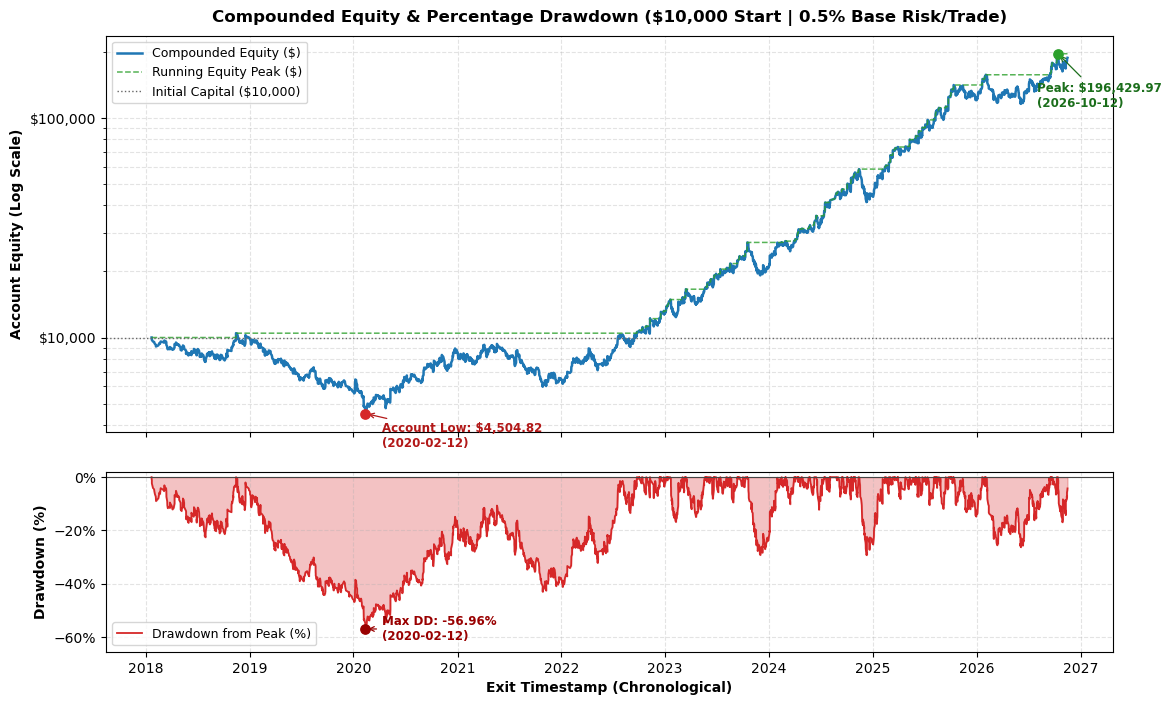

In [133]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd

time_col = next(
    (
        c
        for c in ["exit_time", "close_time", "timestamp", "datetime", "date", "time"]
        if c in df.columns
    ),
    None,
)
if time_col is None:
    raise KeyError(f"Could not find exit/timestamp column. Available columns: {list(df.columns)}")

ts_exit = pd.to_datetime(df[time_col], errors="coerce")
if ts_exit.isna().all():
    raise ValueError(f"Could not parse timestamps from column '{time_col}'.")

# Sort chronologically by exit timestamp (mergesort preserves original order on ties)
order = np.argsort(ts_exit.to_numpy(), kind="mergesort")
r_seq_full = df["R"].to_numpy(dtype=float)[order]
ts_exit_full = ts_exit.iloc[order].reset_index(drop=True)

# Compounded equity curve starting at $10,000 with 0.5% base risk per trade — strict ruin stop
init_cap = 10_000.0
risk_pct = 0.005

equity_list = [init_cap]
exec_times = [ts_exit_full.iloc[0]]

for i, r_val in enumerate(r_seq_full):
    cur_eq = equity_list[-1]
    if cur_eq <= 0.0:
        break
    next_eq = cur_eq + r_val * (cur_eq * risk_pct)
    if next_eq <= 0.0:
        equity_list.append(0.0)
        exec_times.append(ts_exit_full.iloc[i])
        break
    equity_list.append(next_eq)
    exec_times.append(ts_exit_full.iloc[i])

equity = np.array(equity_list, dtype=float)
times = pd.DatetimeIndex(exec_times)

peak_eq = np.maximum.accumulate(equity)
dd_pct = np.where(peak_eq > 0, (equity - peak_eq) / peak_eq * 100.0, 0.0)

peak_idx = int(np.argmax(equity))
low_idx = int(np.argmin(equity))
max_dd_idx = int(np.argmin(dd_pct))

fig, (ax_eq, ax_dd) = plt.subplots(
    2,
    1,
    figsize=(13, 8),
    sharex=True,
    gridspec_kw={"height_ratios": [2.2, 1.0], "hspace": 0.14},
)

# Top panel: Compounded Equity Curve (log scale captures early drawdown + late compounding clearly)
ax_eq.plot(times, equity, color="#1f77b4", linewidth=1.8, label="Compounded Equity ($)")
ax_eq.plot(
    times,
    peak_eq,
    color="#2ca02c",
    linewidth=1.1,
    linestyle="--",
    alpha=0.8,
    label="Running Equity Peak ($)",
)
ax_eq.axhline(init_cap, color="#666666", linewidth=1.0, linestyle=":", label="Initial Capital ($10,000)")

ax_eq.scatter(times[peak_idx], equity[peak_idx], color="#2ca02c", zorder=5, s=45)
ax_eq.annotate(
    f"Peak: ${equity[peak_idx]:,.2f}\n({times[peak_idx].strftime('%Y-%m-%d')})",
    xy=(times[peak_idx], equity[peak_idx]),
    xytext=(-15, -38),
    textcoords="offset points",
    fontsize=8.5,
    fontweight="bold",
    color="#1b6e1b",
    arrowprops=dict(arrowstyle="->", color="#1b6e1b", lw=0.9),
)

ax_eq.scatter(times[low_idx], equity[low_idx], color="#d62728", zorder=5, s=45)
ax_eq.annotate(
    f"Account Low: ${equity[low_idx]:,.2f}\n({times[low_idx].strftime('%Y-%m-%d')})",
    xy=(times[low_idx], equity[low_idx]),
    xytext=(12, -24),
    textcoords="offset points",
    fontsize=8.5,
    fontweight="bold",
    color="#b21818",
    arrowprops=dict(arrowstyle="->", color="#b21818", lw=0.9),
)

ax_eq.set_yscale("log")
ax_eq.yaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}"))
ax_eq.set_ylabel("Account Equity (Log Scale)", fontsize=10, fontweight="bold")
ax_eq.set_title(
    f"Compounded Equity & Percentage Drawdown ($10,000 Start | {risk_pct:.1%} Base Risk/Trade)",
    fontsize=12,
    fontweight="bold",
    pad=10,
)
ax_eq.grid(True, which="both", linestyle="--", alpha=0.35)
ax_eq.legend(loc="upper left", frameon=True, fontsize=9)

# Bottom panel: Percentage Drawdown from Running Peak
ax_dd.fill_between(times, dd_pct, 0.0, color="#d62728", alpha=0.28)
ax_dd.plot(times, dd_pct, color="#d62728", linewidth=1.3, label="Drawdown from Peak (%)")
ax_dd.axhline(0.0, color="#444444", linewidth=0.8)

ax_dd.scatter(times[max_dd_idx], dd_pct[max_dd_idx], color="#990000", zorder=5, s=45)
ax_dd.annotate(
    f"Max DD: {dd_pct[max_dd_idx]:.2f}%\n({times[max_dd_idx].strftime('%Y-%m-%d')})",
    xy=(times[max_dd_idx], dd_pct[max_dd_idx]),
    xytext=(12, -8),
    textcoords="offset points",
    fontsize=8.5,
    fontweight="bold",
    color="#990000",
    arrowprops=dict(arrowstyle="->", color="#990000", lw=0.9),
)

ax_dd.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax_dd.set_ylabel("Drawdown (%)", fontsize=10, fontweight="bold")
ax_dd.set_xlabel("Exit Timestamp (Chronological)", fontsize=10, fontweight="bold")
ax_dd.set_ylim(min(dd_pct.min() * 1.15, -5.0), 2.0)
ax_dd.grid(True, linestyle="--", alpha=0.35)
ax_dd.legend(loc="lower left", frameon=True, fontsize=9)

plt.tight_layout()
plt.show()

Test 5A (Visual): Linear-Scale Compounded Equity & Binary Underwater Indicator ($10,000 Initial Capital, 0.5% Base Risk)

C:\Users\User\AppData\Local\Temp\ipykernel_1976\723727741.py:124: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


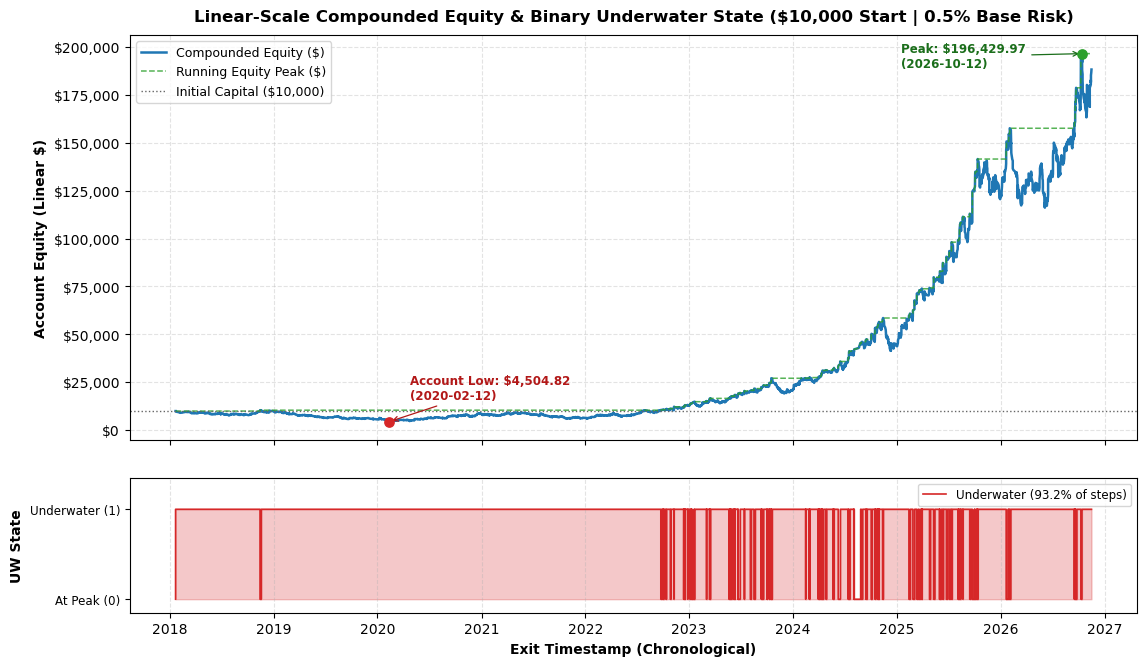

In [136]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd

time_col = next(
    (
        c
        for c in ["exit_time", "close_time", "timestamp", "datetime", "date", "time"]
        if c in df.columns
    ),
    None,
)
if time_col is None:
    raise KeyError(f"Could not find exit/timestamp column. Available columns: {list(df.columns)}")

ts_exit = pd.to_datetime(df[time_col], errors="coerce")
if ts_exit.isna().all():
    raise ValueError(f"Could not parse timestamps from column '{time_col}'.")

# Sort chronologically by exit timestamp (mergesort preserves original order on ties)
order = np.argsort(ts_exit.to_numpy(), kind="mergesort")
r_seq_full = df["R"].to_numpy(dtype=float)[order]
ts_exit_full = ts_exit.iloc[order].reset_index(drop=True)

# Compounded equity curve starting at $10,000 with 0.5% base risk per trade — strict ruin stop
init_cap = 10_000.0
risk_pct = 0.005

equity_list = [init_cap]
exec_times = [ts_exit_full.iloc[0]]

for i, r_val in enumerate(r_seq_full):
    cur_eq = equity_list[-1]
    if cur_eq <= 0.0:
        break
    next_eq = cur_eq + r_val * (cur_eq * risk_pct)
    if next_eq <= 0.0:
        equity_list.append(0.0)
        exec_times.append(ts_exit_full.iloc[i])
        break
    equity_list.append(next_eq)
    exec_times.append(ts_exit_full.iloc[i])

equity = np.array(equity_list, dtype=float)
times = pd.DatetimeIndex(exec_times)

peak_eq = np.maximum.accumulate(equity)
# Binary underwater indicator: 1 when strictly below running peak, 0 at or above peak
is_underwater = (equity < peak_eq).astype(int)
uw_share_pct = float(np.mean(is_underwater) * 100.0)

peak_idx = int(np.argmax(equity))
low_idx = int(np.argmin(equity))

fig, (ax_eq, ax_uw) = plt.subplots(
    2,
    1,
    figsize=(13, 7.5),
    sharex=True,
    gridspec_kw={"height_ratios": [2.4, 0.8], "hspace": 0.14},
)

# Top panel: Linear-scale compounded equity curve
ax_eq.plot(times, equity, color="#1f77b4", linewidth=1.8, label="Compounded Equity ($)")
ax_eq.plot(
    times,
    peak_eq,
    color="#2ca02c",
    linewidth=1.1,
    linestyle="--",
    alpha=0.8,
    label="Running Equity Peak ($)",
)
ax_eq.axhline(init_cap, color="#666666", linewidth=1.0, linestyle=":", label="Initial Capital ($10,000)")

ax_eq.scatter(times[peak_idx], equity[peak_idx], color="#2ca02c", zorder=5, s=45)
ax_eq.annotate(
    f"Peak: ${equity[peak_idx]:,.2f}\n({times[peak_idx].strftime('%Y-%m-%d')})",
    xy=(times[peak_idx], equity[peak_idx]),
    xytext=(-130, -10),
    textcoords="offset points",
    fontsize=8.5,
    fontweight="bold",
    color="#1b6e1b",
    arrowprops=dict(arrowstyle="->", color="#1b6e1b", lw=0.9),
)

ax_eq.scatter(times[low_idx], equity[low_idx], color="#d62728", zorder=5, s=45)
ax_eq.annotate(
    f"Account Low: ${equity[low_idx]:,.2f}\n({times[low_idx].strftime('%Y-%m-%d')})",
    xy=(times[low_idx], equity[low_idx]),
    xytext=(15, 16),
    textcoords="offset points",
    fontsize=8.5,
    fontweight="bold",
    color="#b21818",
    arrowprops=dict(arrowstyle="->", color="#b21818", lw=0.9),
)

ax_eq.yaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}"))
ax_eq.set_ylabel("Account Equity (Linear $)", fontsize=10, fontweight="bold")
ax_eq.set_title(
    f"Linear-Scale Compounded Equity & Binary Underwater State ($10,000 Start | {risk_pct:.1%} Base Risk)",
    fontsize=12,
    fontweight="bold",
    pad=10,
)
ax_eq.grid(True, linestyle="--", alpha=0.35)
ax_eq.legend(loc="upper left", frameon=True, fontsize=9)

# Bottom panel: Binary underwater state (1 = below running peak, 0 = at new peak)
ax_uw.step(times, is_underwater, where="post", color="#d62728", linewidth=1.2, label=f"Underwater ({uw_share_pct:.1f}% of steps)")
ax_uw.fill_between(times, is_underwater, 0, step="post", color="#d62728", alpha=0.25)

ax_uw.set_yticks([0, 1])
ax_uw.set_yticklabels(["At Peak (0)", "Underwater (1)"], fontsize=8.5)
ax_uw.set_ylim(-0.15, 1.35)
ax_uw.set_ylabel("UW State", fontsize=10, fontweight="bold")
ax_uw.set_xlabel("Exit Timestamp (Chronological)", fontsize=10, fontweight="bold")
ax_uw.grid(True, axis="x", linestyle="--", alpha=0.35)
ax_uw.legend(loc="upper right", frameon=True, fontsize=8.5)

plt.tight_layout()
plt.show()

Test 5A (Visual): Risk-Tier Compounding Frontier (0.25% to 5.0% Base Risk with Strict Ruin Stop)

C:\Users\User\AppData\Local\Temp\ipykernel_1976\2079415454.py:135: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


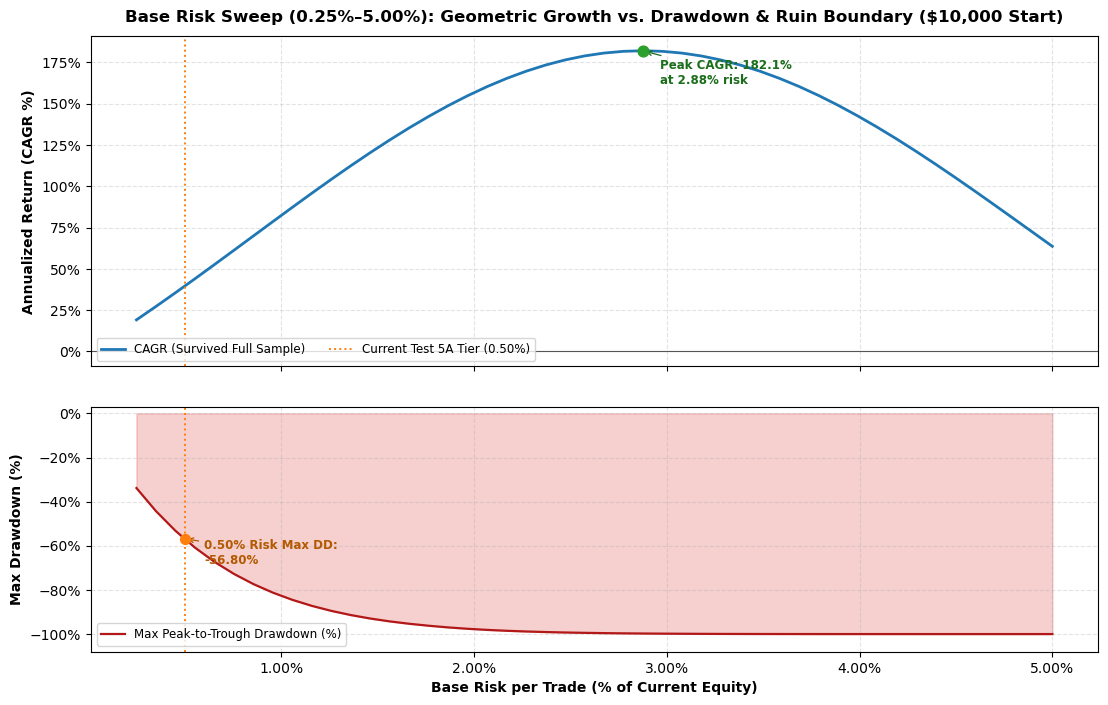

In [139]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd

time_col = next(
    (
        c
        for c in ["exit_time", "close_time", "timestamp", "datetime", "date", "time"]
        if c in df.columns
    ),
    None,
)
if time_col is None:
    raise KeyError(f"Could not find exit/timestamp column. Available columns: {list(df.columns)}")

ts_exit = pd.to_datetime(df[time_col], errors="coerce")
if ts_exit.isna().all():
    raise ValueError(f"Could not parse timestamps from column '{time_col}'.")

order = np.argsort(ts_exit.to_numpy(), kind="mergesort")
r_seq_full = df["R"].to_numpy(dtype=float)[order]
ts_exit_s = ts_exit.iloc[order].reset_index(drop=True)

init_cap = 10_000.0
years_span = max((ts_exit_s.iloc[-1] - ts_exit_s.iloc[0]).total_seconds() / (365.25 * 86400.0), 1e-9)

risk_grid = np.linspace(0.0025, 0.05, 48)  # 0.25% to 5.00%
final_eqs = np.empty_like(risk_grid)
cagrs = np.empty_like(risk_grid)
max_dds_pct = np.empty_like(risk_grid)
ruined_flags = np.zeros(len(risk_grid), dtype=bool)

for idx, f_risk in enumerate(risk_grid):
    eq = init_cap
    peak = init_cap
    worst_dd = 0.0
    is_ruined = False

    for r_val in r_seq_full:
        if eq <= 0.0:
            is_ruined = True
            eq = 0.0
            break
        eq = eq + r_val * (eq * f_risk)
        if eq <= 0.0:
            eq = 0.0
            worst_dd = -100.0
            is_ruined = True
            break
        if eq > peak:
            peak = eq
        dd = (eq - peak) / peak * 100.0
        if dd < worst_dd:
            worst_dd = dd

    final_eqs[idx] = eq
    max_dds_pct[idx] = worst_dd
    ruined_flags[idx] = is_ruined
    cagrs[idx] = -100.0 if is_ruined else ((eq / init_cap) ** (1.0 / years_span) - 1.0) * 100.0

fig, (ax_top, ax_bot) = plt.subplots(
    2,
    1,
    figsize=(13, 8),
    sharex=True,
    gridspec_kw={"height_ratios": [1.35, 1.0], "hspace": 0.14},
)

x_pct = risk_grid * 100.0
surv_mask = ~ruined_flags

# Top panel: CAGR (%) across base risk tiers + mark 0.5% audit tier and peak CAGR
ax_top.plot(x_pct[surv_mask], cagrs[surv_mask], color="#1f77b4", linewidth=2.0, label="CAGR (Survived Full Sample)")
if np.any(ruined_flags):
    ruin_x = x_pct[ruined_flags]
    ax_top.axvline(ruin_x[0], color="#d62728", linestyle="--", linewidth=1.3, label=f"Ruin Threshold (~{ruin_x[0]:.2f}%)")
    ax_top.axvspan(ruin_x[0], x_pct[-1], color="#d62728", alpha=0.10)
    ax_top.scatter(ruin_x, np.full_like(ruin_x, -100.0), color="#d62728", s=22, zorder=5, label="Account Ruined (-100%)")

best_i = int(np.argmax(cagrs))
ax_top.scatter([x_pct[best_i]], [cagrs[best_i]], color="#2ca02c", s=60, zorder=6)
ax_top.annotate(
    f"Peak CAGR: {cagrs[best_i]:.1f}%\nat {x_pct[best_i]:.2f}% risk",
    xy=(x_pct[best_i], cagrs[best_i]),
    xytext=(12, -24),
    textcoords="offset points",
    fontsize=8.5,
    fontweight="bold",
    color="#1b6e1b",
    arrowprops=dict(arrowstyle="->", color="#1b6e1b", lw=0.9),
)

ax_top.axvline(0.5, color="#ff7f0e", linestyle=":", linewidth=1.4, label="Current Test 5A Tier (0.50%)")
ax_top.axhline(0.0, color="#555555", linewidth=0.8)
ax_top.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax_top.set_ylabel("Annualized Return (CAGR %)", fontsize=10, fontweight="bold")
ax_top.set_title(
    "Base Risk Sweep (0.25%–5.00%): Geometric Growth vs. Drawdown & Ruin Boundary ($10,000 Start)",
    fontsize=12,
    fontweight="bold",
    pad=10,
)
ax_top.grid(True, linestyle="--", alpha=0.35)
ax_top.legend(loc="lower left", ncol=2, frameon=True, fontsize=8.5)

# Bottom panel: Max Drawdown (%) across base risk tiers
ax_bot.fill_between(x_pct, max_dds_pct, 0.0, color="#d62728", alpha=0.22)
ax_bot.plot(x_pct, max_dds_pct, color="#b21818", linewidth=1.6, label="Max Peak-to-Trough Drawdown (%)")
ax_bot.axvline(0.5, color="#ff7f0e", linestyle=":", linewidth=1.4)
if np.any(ruined_flags):
    ax_bot.axvline(x_pct[ruined_flags][0], color="#d62728", linestyle="--", linewidth=1.3)

dd_05 = float(np.interp(0.5, x_pct, max_dds_pct))
ax_bot.scatter([0.5], [dd_05], color="#ff7f0e", s=50, zorder=6)
ax_bot.annotate(
    f"0.50% Risk Max DD:\n{dd_05:.2f}%",
    xy=(0.5, dd_05),
    xytext=(14, -18),
    textcoords="offset points",
    fontsize=8.5,
    fontweight="bold",
    color="#b35900",
    arrowprops=dict(arrowstyle="->", color="#b35900", lw=0.9),
)

ax_bot.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=2))
ax_bot.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax_bot.set_xlabel("Base Risk per Trade (% of Current Equity)", fontsize=10, fontweight="bold")
ax_bot.set_ylabel("Max Drawdown (%)", fontsize=10, fontweight="bold")
ax_bot.set_ylim(-108.0, 3.0)
ax_bot.grid(True, linestyle="--", alpha=0.35)
ax_bot.legend(loc="lower left", frameon=True, fontsize=8.5)

plt.tight_layout()
plt.show()